# Phase 2 -- LoRA vs AdaLoRA vs DoRA Comparison

**Notebook:** `03_phase2_peft_comparison.ipynb`
**Depends on:** a completed `02_phase1_lora_proper.ipynb` run (its saved
result JSON and fixed evaluation indices are loaded and reused here, not
recomputed). `01_phase1_lora.ipynb` and `02_phase1_lora_proper.ipynb` are
**not modified or executed** by this notebook.

## Research question

Under controlled experimental conditions, how do **LoRA**, **AdaLoRA**, and
**DoRA** compare in: SAMSum target-task learning, BoolQ forgetting, PIQA
forgetting, trainable-parameter efficiency, training time, and peak GPU
memory? The **only** variable intended to explain a difference between arms
is the PEFT method itself. Data, prompts, scoring, seed, learning rate, epochs,
sequence length, effective batch size, and optimizer-step count are controlled.
For T4 VRAM safety, Phase 2 uses micro-batch 2 x accumulation 8 while the saved
Phase 1 LoRA run used 4 x 4; both have effective batch size 16.

## Why LoRA is not retrained here

`02_phase1_lora_proper.ipynb`'s completed run **is** the "fresh Qwen -> LoRA"
arm of this comparison -- same base model and same fixed evaluation sets. Phase 2 preserves the same effective
batch size and optimizer-step count while using a smaller T4-safe physical micro-batch. Re-running it
would waste Colab time reproducing a number we already have. This notebook
loads that result directly (Part J) and validates its configuration actually
matches Part A's configuration before treating it as comparable (Part C/K) --
it does not just assume the comparison is controlled.

## Notebook structure (Parts A-L)

```
PART A  Environment and configuration
PART B  Load datasets and fixed evaluation indices (REUSED from Phase 1 Proper)
PART C  Load/reuse canonical PRE baseline (from Phase 1 Proper's result)
PART D  AdaLoRA implementation validation      <- internal engineering gate
PART E  AdaLoRA proper experiment
PART F  GPU cleanup (AdaLoRA)
PART G  DoRA implementation validation         <- internal engineering gate
PART H  DoRA proper experiment
PART I  GPU cleanup (DoRA)
PART J  Load Phase 1 Proper LoRA result
PART K  LoRA vs AdaLoRA vs DoRA comparison
PART L  Tables, plots, and interpretation
```

**Parts D and G are hard gates.** Each ends with an `assert` that must pass
before its corresponding proper experiment (E / H) runs. If a gate's
evidence check fails, the assertion raises and the notebook halts there --
by design, not by accident. See each Part's markdown for exactly what
evidence is required and why (this matters a lot for AdaLoRA specifically --
see Part D).

## Fairness -- View A only

This run uses **View A: same nominal rank** (`r=8` / `target_r=8` for all
three). This does **not** mean equal trainable-parameter counts -- LoRA,
AdaLoRA, and DoRA have three different actual parameter counts at "rank 8,"
and every result row reports the *measured* count, never an assumed one.
View B (trainable-parameter-budget-matched reruns) is explicitly **not**
performed here -- optional future work.

## Single-run caveat

Every number in this notebook comes from **one run per method, one seed**.
Do not read a smaller forgetting gap as "this method is better" -- Part L's
interpretation section exists specifically to guard against that.


## PART A.1 -- Install Dependencies

Same install cell as Phase 1, including the validated `torchao` fix: Colab's
preinstalled `torchao` is older than what current `peft` checks for and is
not needed for this project (no quantization anywhere in Phase 1 or Phase 2)
-- so it's uninstalled rather than upgraded.


In [1]:
!pip install -q -U "transformers>=4.44" "datasets>=2.19" "peft>=0.11" accelerate evaluate rouge_score

# torchao is not required for standard (non-quantized) LoRA/AdaLoRA/DoRA --
# see markdown above. Uninstalling Colab's preinstalled, version-incompatible
# copy avoids a spurious ImportError from PEFT's optional torchao integration.
!pip uninstall -y -q torchao


  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.3/12.3 MB 80.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 559.1/559.1 kB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 394.3/394.3 kB 25.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 8.5 MB/s eta 0:00:00


**IMPORTANT -- restart the Colab runtime now**, then re-run from the top.
Package changes don't take effect in an already-running kernel. This is
needed once per fresh environment, not before every run.


## PART A.2 -- Imports

Centralizes every import used anywhere in this notebook, including `gc`
(used repeatedly for the memory-cleanup stages in Parts D/F/G/I).


In [2]:
import sys
import gc
import json
import math
import time
import random
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

import transformers
import peft
import evaluate as hf_evaluate
from datasets import load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    TrainerCallback,
)
from peft import LoraConfig, AdaLoraConfig, get_peft_model, TaskType, PeftModel


def stage(title: str) -> None:
    """Prints a clean stage banner. Used to keep notebook output readable
    without flooding it with unstructured logs."""
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)


def print_gpu_memory(label: str) -> None:
    """Shared memory-observation helper -- called before/after every
    cleanup and every fresh model load in this notebook (Parts D-I)."""
    if torch.cuda.is_available():
        allocated_mb = torch.cuda.memory_allocated() / (1024 ** 2)
        reserved_mb = torch.cuda.memory_reserved() / (1024 ** 2)
        print(f"[GPU memory] {label}: allocated={allocated_mb:.1f} MB, reserved={reserved_mb:.1f} MB")
    else:
        print(f"[GPU memory] {label}: CUDA not available -- skipping.")


print("Imports OK.")


Imports OK.


## Resume-safe Google Drive storage
This version writes training checkpoints and completed adapters/results to Google Drive so a Colab VM reset does not erase expensive work. On a new runtime, rerun the notebook from the top; completed training can resume from the latest Drive checkpoint.


In [3]:
# Mount persistent Google Drive storage for Phase 2
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

PERSIST_ROOT = Path('/content/drive/MyDrive/forgetting-aware-peft/phase2_resume')
PERSIST_CHECKPOINTS = PERSIST_ROOT / 'checkpoints'
PERSIST_ADAPTERS = PERSIST_ROOT / 'adapters'
PERSIST_RESULTS = PERSIST_ROOT / 'results'
for _d in (PERSIST_CHECKPOINTS, PERSIST_ADAPTERS, PERSIST_RESULTS):
    _d.mkdir(parents=True, exist_ok=True)
print('Persistent Phase 2 root:', PERSIST_ROOT)

def latest_checkpoint(folder: Path):
    candidates=[]
    if folder.exists():
        for p in folder.glob('checkpoint-*'):
            try: candidates.append((int(p.name.split('-')[-1]), p))
            except ValueError: pass
    return max(candidates, default=(None,None))[1]

def latest_adapter(method: str):
    xs=sorted(PERSIST_ADAPTERS.glob(f'*_{method}_phase2_proper'))
    return xs[-1] if xs else None

print('Existing AdaLoRA checkpoint:', latest_checkpoint(PERSIST_CHECKPOINTS/'adalora_proper'))
print('Existing DoRA checkpoint:', latest_checkpoint(PERSIST_CHECKPOINTS/'dora_proper'))
print('Existing AdaLoRA adapter:', latest_adapter('adalora'))
print('Existing DoRA adapter:', latest_adapter('dora'))


Mounted at /content/drive
Persistent Phase 2 root: /content/drive/MyDrive/forgetting-aware-peft/phase2_resume
Existing AdaLoRA checkpoint: None
Existing DoRA checkpoint: None
Existing AdaLoRA adapter: None
Existing DoRA adapter: None


## PART A.3 -- Configuration

Two configs: `config` (the Phase 1 Proper-matching settings, used for the
AdaLoRA-proper and DoRA-proper experiments) and `val_config` (a tiny
validation-scale config, used only by Parts D and G's engineering gates --
mirrors Phase 1's original smoke-test scale exactly, since that's already
proven cheap and sufficient to catch implementation bugs).

`config` preserves Phase 1 Proper's model, data, epochs, learning rate, sequence length,
effective batch size (=16), and optimizer-step count. For T4 memory safety only, the
physical micro-batch is 2 with gradient accumulation 8 instead of 4 x 4. Part C
checks the scientifically important controlled fields and verifies effective batch size.


In [4]:
from dataclasses import dataclass, field
from typing import List

TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]


@dataclass
class ProperConfig:
    """T4-safe Phase 2 settings. The physical micro-batch is reduced from 4 to 2
    and gradient accumulation increased from 4 to 8, preserving the same
    effective batch size of 16 and the same 250 optimizer steps as Phase 1 Proper."""
    seed: int = 42
    base_model_id: str = "Qwen/Qwen2.5-0.5B"

    samsum_train_samples: int = 2000
    samsum_eval_samples: int = 200
    samsum_max_length: int = 512
    samsum_gen_max_new_tokens: int = 64

    boolq_probe_samples: int = 500
    piqa_probe_samples: int = 500
    probe_max_length: int = 256

    epochs: int = 2
    per_device_train_batch_size: int = 2
    gradient_accumulation_steps: int = 8
    learning_rate: float = 2e-4

    lora_target_modules: List[str] = field(default_factory=lambda: list(TARGET_MODULES))


@dataclass
class ValidationConfig:
    """Tiny engineering-gate scale for Parts D and G -- mirrors Phase 1's
    original smoke test exactly (100 train examples, 1 epoch, ~50 steps)."""
    seed: int = 42
    base_model_id: str = "Qwen/Qwen2.5-0.5B"

    samsum_train_samples: int = 100
    samsum_max_length: int = 256
    samsum_gen_max_new_tokens: int = 64

    epochs: int = 1
    per_device_train_batch_size: int = 2
    gradient_accumulation_steps: int = 1

    lora_target_modules: List[str] = field(default_factory=lambda: list(TARGET_MODULES))


config = ProperConfig()
val_config = ValidationConfig()


def compute_optimization_steps(n_examples: int, per_device_batch: int, grad_accum: int, epochs: int) -> int:
    """Matches HF Trainer's own step-counting formula. Validated against
    Phase 1 Proper's actual reported step counts: smoke test
    (100, 2, 1, 1) -> 50 steps (matches); Phase 1 Proper (2000, 4, 4, 2)
    -> 250 steps (matches)."""
    steps_per_epoch = math.ceil(n_examples / (per_device_batch * grad_accum))
    return steps_per_epoch * epochs


proper_total_steps = compute_optimization_steps(
    config.samsum_train_samples, config.per_device_train_batch_size,
    config.gradient_accumulation_steps, config.epochs,
)
val_total_steps = compute_optimization_steps(
    val_config.samsum_train_samples, val_config.per_device_train_batch_size,
    val_config.gradient_accumulation_steps, val_config.epochs,
)

print("ProperConfig:")
for k, v in config.__dict__.items():
    print(f"  {k:28s}: {v}")
print(f"  {'computed optimization_steps':28s}: {proper_total_steps}")

print("\nValidationConfig:")
for k, v in val_config.__dict__.items():
    print(f"  {k:28s}: {v}")
print(f"  {'computed optimization_steps':28s}: {val_total_steps}")


ProperConfig:
  seed                        : 42
  base_model_id               : Qwen/Qwen2.5-0.5B
  samsum_train_samples        : 2000
  samsum_eval_samples         : 200
  samsum_max_length           : 512
  samsum_gen_max_new_tokens   : 64
  boolq_probe_samples         : 500
  piqa_probe_samples          : 500
  probe_max_length            : 256
  epochs                      : 2
  per_device_train_batch_size : 2
  gradient_accumulation_steps : 8
  learning_rate               : 0.0002
  lora_target_modules         : ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj']
  computed optimization_steps : 250

ValidationConfig:
  seed                        : 42
  base_model_id               : Qwen/Qwen2.5-0.5B
  samsum_train_samples        : 100
  samsum_max_length           : 256
  samsum_gen_max_new_tokens   : 64
  epochs                      : 1
  per_device_train_batch_size : 2
  gradient_accumulation_steps : 1
  lora_target_modules         : ['q_proj', 'k_pro

## PART A.4 -- Check GPU / Environment

Same checks as Phase 1 (versions, CUDA/precision detection, `torchao`
status) -- identical code, since the environment requirements haven't
changed.


In [5]:
stage("Environment check")

print(f"Python version      : {sys.version.split()[0]}")
print(f"PyTorch version      : {torch.__version__}")
print(f"Transformers version : {transformers.__version__}")
print(f"PEFT version         : {peft.__version__}")

try:
    import torchao
    from packaging import version as _pkg_version
    torchao_ok = _pkg_version.parse(torchao.__version__) >= _pkg_version.parse("0.16.0")
    print(f"torchao version      : {torchao.__version__} (present, but NOT required by this project)")
    if not torchao_ok:
        print("*** WARNING: an old, incompatible torchao is installed and may break get_peft_model().")
        print("*** Re-run Part A.1's install cell (which uninstalls torchao) and RESTART THE RUNTIME.")
except ImportError:
    print("torchao version      : not installed (expected -- this project uses standard, non-quantized PEFT)")

cuda_available = torch.cuda.is_available()
print(f"CUDA available       : {cuda_available}")

if cuda_available:
    device = torch.device("cuda")
    gpu_name = torch.cuda.get_device_name(0)
    total_vram_gb = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
    print(f"GPU                  : {gpu_name}")
    print(f"Total GPU VRAM       : {total_vram_gb:.1f} GB")

    use_bf16 = torch.cuda.is_bf16_supported()
    use_fp16 = not use_bf16
    print(f"bf16 supported       : {use_bf16}  -> training precision: {'bf16' if use_bf16 else 'fp16'}")
else:
    device = torch.device("cpu")
    use_bf16 = False
    use_fp16 = False
    print()
    print("*** WARNING: No GPU detected. This notebook trains 4 models (2 validation, 2 proper)")
    print("*** and REQUIRES a GPU to finish in reasonable time.")

print(f"\nSelected device      : {device}")



Environment check
Python version      : 3.13.15
PyTorch version      : 2.11.0+cu128
Transformers version : 5.17.0
PEFT version         : 0.20.0
torchao version      : not installed (expected -- this project uses standard, non-quantized PEFT)
CUDA available       : True
GPU                  : Tesla T4
Total GPU VRAM       : 14.6 GB
bf16 supported       : True  -> training precision: bf16

Selected device      : cuda


## PART A.5 -- Reproducibility / Random Seeds


In [6]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    transformers.set_seed(seed)


set_seed(config.seed)
print(f"Seed set to {config.seed} for random, numpy, torch, cuda, and transformers.")


Seed set to 42 for random, numpy, torch, cuda, and transformers.


## PART A.6 -- Output Directory & Optional Google Drive

**This must point at the SAME `OUTPUT_ROOT` that `02_phase1_lora_proper.ipynb`
used**, or Part B/C cannot find its saved indices/results. If Phase 1 Proper
used `USE_DRIVE = True`, set it here too. If it ran on local Colab storage in
a still-live runtime, this notebook must run in that same runtime.


In [7]:
from pathlib import Path

# ============================================================
# Project paths
# ============================================================

# Keep the outputs folder beside this notebook.
# Works locally when the forgetting-aware-peft folder is opened
# as the VS Code / Jupyter working directory.
OUTPUT_ROOT = Path("./outputs")

ADAPTER_DIR = OUTPUT_ROOT / "adapters"
RESULTS_DIR = OUTPUT_ROOT / "results"

# Phase 1 Proper fixed evaluation indices -- READ ONLY.
# Phase 2 MUST reuse these exact sets.
PHASE1_PROPER_INDICES_DIR = (
    OUTPUT_ROOT / "indices" / "phase1_proper"
)

# Create output directories if needed.
# Do NOT create/re-sample the Phase 1 indices here.
for d in (ADAPTER_DIR, RESULTS_DIR):
    d.mkdir(parents=True, exist_ok=True)

print(f"OUTPUT_ROOT = {OUTPUT_ROOT.resolve()}")
print(
    f"PHASE1_PROPER_INDICES_DIR = "
    f"{PHASE1_PROPER_INDICES_DIR.resolve()}"
)

# Verify required Phase 1 files
required_index_files = [
    "boolq_indices.json",
    "piqa_indices.json",
    "samsum_eval_indices.json",
]

print("\nChecking Phase 1 Proper index files:")

for filename in required_index_files:
    path = PHASE1_PROPER_INDICES_DIR / filename
    print(f"  {filename}: {'FOUND' if path.exists() else 'MISSING'}")

OUTPUT_ROOT = /content/outputs
PHASE1_PROPER_INDICES_DIR = /content/outputs/indices/phase1_proper

Checking Phase 1 Proper index files:
  boolq_indices.json: MISSING
  piqa_indices.json: MISSING
  samsum_eval_indices.json: MISSING


## PART B -- Load Datasets and Fixed Evaluation Indices

Same dataset-loading code as Phase 1 (including the `lighteval/piqa` fix),
copied verbatim -- identical `datasets` calls, identical fallback candidate
lists, identical column checks.

**Fixed indices are loaded, never sampled.** Unlike Phase 1's
`sample_fixed_indices` (which creates new indices if none exist yet), this
notebook uses a stricter loader that **fails loudly** if Phase 1 Proper's
500/500/200-example index files aren't found -- silently generating a new
sample here would violate the "same evaluation examples as Phase 1 Proper"
requirement without any visible error.


In [8]:
stage("Loading datasets")


def _try_load_dataset(name: str):
    try:
        return load_dataset(name)
    except Exception:
        return load_dataset(name, trust_remote_code=True)


def load_dataset_with_fallback(candidates, task_name):
    last_error = None
    for name in candidates:
        try:
            ds = _try_load_dataset(name)
            print(f"Loaded {task_name} from '{name}'")
            return ds, name
        except Exception as e:
            last_error = e
            print(f"  could not load {task_name} from '{name}': {type(e).__name__}: {e}")
    raise RuntimeError(
        f"Failed to load {task_name} from any candidate source {candidates}. "
        f"Last error: {last_error}"
    )


def _assert_columns(dataset_split, required_columns, task_name):
    missing = [c for c in required_columns if c not in dataset_split.column_names]
    if missing:
        raise ValueError(
            f"{task_name} dataset is missing expected column(s) {missing}. "
            f"Found columns: {dataset_split.column_names}."
        )


samsum_ds, samsum_source = load_dataset_with_fallback(
    ["samsum", "knkarthick/samsum", "Samsung/samsum"], "SAMSum"
)
boolq_ds, boolq_source = load_dataset_with_fallback(
    ["google/boolq", "boolq"], "BoolQ"
)
piqa_ds, piqa_source = load_dataset_with_fallback(
    ["lighteval/piqa"], "PIQA"
)

_assert_columns(samsum_ds["train"], ["dialogue", "summary"], "SAMSum")
_assert_columns(boolq_ds["validation"], ["question", "answer", "passage"], "BoolQ")
_assert_columns(piqa_ds["validation"], ["goal", "sol1", "sol2", "label"], "PIQA")

print("\nDataset sources actually used (compared against Phase 1 Proper's in Part C):")
print(f"  SAMSum: {samsum_source}")
print(f"  BoolQ : {boolq_source}")
print(f"  PIQA  : {piqa_source}")



Loading datasets


`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'samsum' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.
ERROR:datasets.load:`trust_remote_code` is not supported anymore.
Please check that the Hugging Face dataset 'samsum' isn't based on a loading script and remove `trust_remote_code`.
If the dataset is based on a loading script, please ask the dataset author to remove it and convert it to a standard format like Parquet.


  could not load SAMSum from 'samsum': DatasetNotFoundError: Dataset 'samsum' doesn't exist on the Hub or cannot be accessed.


README.md:   0%|          | 0.00/4.36k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/9.26M [00:00<?, ?B/s]

...

plain_text/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/16113 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3084 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1838 [00:00<?, ? examples/s]

Loaded PIQA from 'lighteval/piqa'

Dataset sources actually used (compared against Phase 1 Proper's in Part C):
  SAMSum: knkarthick/samsum
  BoolQ : google/boolq
  PIQA  : lighteval/piqa


In [9]:
!unzip -oq /content/outputs.zip -d /content/

In [10]:
from pathlib import Path

files = [
    "/content/outputs/indices/phase1_proper/boolq_indices.json",
    "/content/outputs/indices/phase1_proper/piqa_indices.json",
    "/content/outputs/indices/phase1_proper/samsum_eval_indices.json",
]

for f in files:
    print(f, "→", "FOUND ✅" if Path(f).exists() else "MISSING ❌")

/content/outputs/indices/phase1_proper/boolq_indices.json → FOUND ✅
/content/outputs/indices/phase1_proper/piqa_indices.json → FOUND ✅
/content/outputs/indices/phase1_proper/samsum_eval_indices.json → FOUND ✅


In [11]:
stage("Loading Phase 1 Proper's fixed evaluation indices (read-only reuse)")


def load_required_indices(path: Path) -> list:
    """Unlike Phase 1's sample_fixed_indices, this NEVER creates a new
    sample -- Phase 2 must reuse Phase 1 Proper's exact indices. Missing
    file is a hard error, not a silent fallback to fresh sampling."""
    if not path.exists():
        raise FileNotFoundError(
            f"Required index file not found: {path}\n"
            f"This means 02_phase1_lora_proper.ipynb's indices are not visible here -- "
            f"check USE_DRIVE/OUTPUT_ROOT match (Part A.6), and that it has actually "
            f"finished running. Phase 2 must NOT generate its own indices."
        )
    indices = json.loads(path.read_text())
    print(f"Loaded {len(indices)} indices from {path}")
    return indices


boolq_indices = load_required_indices(PHASE1_PROPER_INDICES_DIR / "boolq_indices.json")
piqa_indices = load_required_indices(PHASE1_PROPER_INDICES_DIR / "piqa_indices.json")
samsum_eval_indices = load_required_indices(PHASE1_PROPER_INDICES_DIR / "samsum_eval_indices.json")

boolq_examples = boolq_ds["validation"].select(boolq_indices)
piqa_examples = piqa_ds["validation"].select(piqa_indices)
samsum_eval_examples = samsum_ds["test"].select(samsum_eval_indices)

assert len(boolq_indices) == config.boolq_probe_samples, (
    f"Loaded {len(boolq_indices)} BoolQ indices but config expects {config.boolq_probe_samples} -- "
    f"config.boolq_probe_samples doesn't match Phase 1 Proper's actual sample size."
)
assert len(piqa_indices) == config.piqa_probe_samples, (
    f"Loaded {len(piqa_indices)} PIQA indices but config expects {config.piqa_probe_samples}."
)
assert len(samsum_eval_indices) == config.samsum_eval_samples, (
    f"Loaded {len(samsum_eval_indices)} SAMSum eval indices but config expects {config.samsum_eval_samples}."
)

print(f"\nReused fixed evaluation sets: BoolQ={len(boolq_examples)}, PIQA={len(piqa_examples)}, "
      f"SAMSum-eval={len(samsum_eval_examples)}")



Loading Phase 1 Proper's fixed evaluation indices (read-only reuse)
Loaded 500 indices from outputs/indices/phase1_proper/boolq_indices.json
Loaded 500 indices from outputs/indices/phase1_proper/piqa_indices.json
Loaded 200 indices from outputs/indices/phase1_proper/samsum_eval_indices.json

Reused fixed evaluation sets: BoolQ=500, PIQA=500, SAMSum-eval=200


## PART B (continued) -- Load Tokenizer

One tokenizer instance, loaded once, reused for every method's validation
and proper run below -- literally the same Python object every time, which
is the strongest possible guarantee of "same tokenizer."


In [12]:
stage("Loading tokenizer")

try:
    tokenizer = AutoTokenizer.from_pretrained(config.base_model_id)
except Exception as e:
    raise RuntimeError(f"Failed to load tokenizer '{config.base_model_id}': {e}") from e

if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    print(f"tokenizer.pad_token was None -> set to eos_token ({tokenizer.eos_token!r})")
else:
    print(f"tokenizer.pad_token already set: {tokenizer.pad_token!r}")



Loading tokenizer


config.json:   0%|          | 0.00/681 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

tokenizer.pad_token already set: '<|endoftext|>'


## PART B (continued) -- Shared Evaluation / Training Functions

Copied verbatim from `02_phase1_lora_proper.ipynb` -- same log-likelihood
scoring, same BoolQ/PIQA prompts, same target-only-loss SAMSum tokenization,
same greedy-decoding generation, same ROUGE computation. Defined **once**
here and reused for AdaLoRA's and DoRA's validation and proper runs alike,
so there is no possibility of the methodology silently drifting between
methods within this notebook.


In [13]:
def continuation_log_likelihood(model, tokenizer, prompt: str, continuation: str, device):
    """
    Returns (sum_log_prob, num_continuation_tokens) for `continuation`
    conditioned on `prompt`, using one teacher-forced forward pass.
    """
    context_ids = tokenizer(prompt, add_special_tokens=False, return_tensors="pt").input_ids[0]
    whole_ids = tokenizer(prompt + continuation, add_special_tokens=False, return_tensors="pt").input_ids[0]
    context_len = context_ids.shape[0]

    if not torch.equal(whole_ids[:context_len], context_ids):
        raise ValueError(
            "Tokenization boundary mismatch between prompt and prompt+continuation. "
            f"prompt={prompt!r} continuation={continuation!r}"
        )

    continuation_ids = whole_ids[context_len:]
    if continuation_ids.shape[0] == 0:
        raise ValueError(f"Continuation tokenized to zero tokens: {continuation!r}")

    input_ids = whole_ids.unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(input_ids=input_ids).logits[0]
    log_probs = F.log_softmax(logits.float(), dim=-1)

    total_log_prob = 0.0
    for i, tok_id in enumerate(continuation_ids):
        pred_pos = context_len + i - 1
        total_log_prob += log_probs[pred_pos, tok_id.item()].item()

    return total_log_prob, continuation_ids.shape[0]


BOOLQ_PROMPT_TEMPLATE = (
    "Passage:\n{passage}\n\n"
    "Question:\n{question}\n\n"
    "Answer:"
)


def truncate_to_token_budget(text: str, tokenizer, max_tokens: int) -> str:
    ids = tokenizer(text, add_special_tokens=False).input_ids
    if len(ids) <= max_tokens:
        return text
    return tokenizer.decode(ids[:max_tokens])


def evaluate_boolq(model, tokenizer, examples, device, max_passage_tokens):
    model.eval()
    n_correct = 0
    n_gold_true = 0
    for ex in examples:
        passage = truncate_to_token_budget(ex["passage"], tokenizer, max_passage_tokens)
        prompt = BOOLQ_PROMPT_TEMPLATE.format(passage=passage, question=ex["question"])
        yes_lp, _ = continuation_log_likelihood(model, tokenizer, prompt, " Yes", device)
        no_lp, _ = continuation_log_likelihood(model, tokenizer, prompt, " No", device)
        predicted = yes_lp > no_lp
        gold = bool(ex["answer"])
        n_correct += int(predicted == gold)
        n_gold_true += int(gold)
    n = len(examples)
    accuracy = n_correct / n
    majority_class_baseline = max(n_gold_true, n - n_gold_true) / n
    return {"accuracy": accuracy, "n_examples": n, "majority_class_baseline": majority_class_baseline}


PIQA_PROMPT_TEMPLATE = "Goal: {goal}\nSolution:"


def evaluate_piqa(model, tokenizer, examples, device):
    model.eval()
    n_correct = 0
    for ex in examples:
        prompt = PIQA_PROMPT_TEMPLATE.format(goal=ex["goal"])
        sol1_lp, sol1_len = continuation_log_likelihood(model, tokenizer, prompt, " " + ex["sol1"], device)
        sol2_lp, sol2_len = continuation_log_likelihood(model, tokenizer, prompt, " " + ex["sol2"], device)
        sol1_avg = sol1_lp / sol1_len
        sol2_avg = sol2_lp / sol2_len
        predicted = 0 if sol1_avg > sol2_avg else 1
        gold = int(ex["label"])
        n_correct += int(predicted == gold)
    return {"accuracy": n_correct / len(examples), "n_examples": len(examples)}


rouge_metric = hf_evaluate.load("rouge")


def build_samsum_prompt(dialogue: str) -> str:
    return f"Summarize the following conversation:\n\n{dialogue}\n\nSummary:\n"


def tokenize_samsum_example(dialogue: str, summary: str, tokenizer, max_length: int):
    prompt = build_samsum_prompt(dialogue)
    target = summary.strip() + tokenizer.eos_token
    prompt_ids = tokenizer(prompt, add_special_tokens=False).input_ids
    target_ids = tokenizer(target, add_special_tokens=False).input_ids
    input_ids = prompt_ids + target_ids
    labels = [-100] * len(prompt_ids) + list(target_ids)
    input_ids = input_ids[:max_length]
    labels = labels[:max_length]
    attention_mask = [1] * len(input_ids)
    pad_len = max_length - len(input_ids)
    if pad_len > 0:
        input_ids = input_ids + [tokenizer.pad_token_id] * pad_len
        labels = labels + [-100] * pad_len
        attention_mask = attention_mask + [0] * pad_len
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


@torch.no_grad()
def generate_summary(model, tokenizer, dialogue: str, device, max_new_tokens: int) -> str:
    prompt = build_samsum_prompt(dialogue)
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(device)
    output_ids = model.generate(
        **inputs, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tokenizer.pad_token_id,
    )
    generated_ids = output_ids[0][inputs["input_ids"].shape[1]:]
    return tokenizer.decode(generated_ids, skip_special_tokens=True).strip()


def evaluate_samsum(model, tokenizer, examples, device, max_new_tokens):
    model.eval()
    predictions, references = [], []
    for ex in examples:
        pred = generate_summary(model, tokenizer, ex["dialogue"], device, max_new_tokens)
        predictions.append(pred)
        references.append(ex["summary"])
    scores = rouge_metric.compute(predictions=predictions, references=references)
    return scores, predictions


def prepare_samsum_training_data(train_samples: int, max_length: int, seed: int):
    """Same deterministic shuffle+select pattern as Phase 1 -- given the
    same samsum_source and seed, selects the identical 2,000 examples in
    the identical order Phase 1 Proper's LoRA run used."""
    raw = samsum_ds["train"].shuffle(seed=seed).select(range(train_samples))
    assert len(raw) > 0, "SAMSum training set is empty."

    def _map_fn(example):
        return tokenize_samsum_example(example["dialogue"], example["summary"], tokenizer, max_length)

    tokenized = raw.map(_map_fn, remove_columns=raw.column_names)
    tokenized.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
    return raw, tokenized


print("Shared evaluation/training functions defined (identical to Phase 1 Proper).")


Shared evaluation/training functions defined (identical to Phase 1 Proper).


## PART C -- Load/Reuse Canonical PRE Baseline

**Why reuse instead of recompute:** PRE is, by definition, the same
untouched base model regardless of which PEFT method trains next. Given our
evaluation is fully deterministic (greedy decoding, log-likelihood scoring,
`model.eval()`, fixed indices, no sampling), recomputing PRE three times
would spend real Colab time reproducing a number we already have from Phase
1 Proper.

**Why not blindly trust it either:** if any controlled-variable assumption
silently breaks (a different dataset mirror resolves, indices drift, a
library version changes), reusing a stale baseline would corrupt every
downstream forgetting-gap number without anything looking obviously wrong.
So this notebook does two things, not one:

1. **Load** Phase 1 Proper's saved PRE metrics and full configuration.
2. **Verify** — both that Phase 1 Proper's configuration actually matches
   this notebook's (below), and, later (Parts E/H), that a freshly-loaded
   Qwen actually reproduces Phase 1 Proper's PRE accuracy before being
   trusted for a proper run.


In [14]:
stage("Locating Phase 1 Proper's result")


def find_phase1_proper_result(results_dir: Path) -> Path:
    """Auto-discovers the most recent Phase 1 Proper LoRA result
    (experiment_id pattern: {timestamp}_lora_phase1_proper.json). Override
    PHASE1_PROPER_RESULT_PATH below if you want a specific run."""
    candidates = sorted(results_dir.glob("*_lora_phase1_proper.json"))
    if not candidates:
        raise FileNotFoundError(
            f"No Phase 1 Proper LoRA result found in {results_dir} "
            f"(expected a file matching '*_lora_phase1_proper.json'). "
            f"02_phase1_lora_proper.ipynb must complete before this notebook can run."
        )
    chosen = candidates[-1]  # lexicographic timestamp sort -> most recent
    if len(candidates) > 1:
        print(f"Found {len(candidates)} Phase 1 Proper results; using the most recent: {chosen.name}")
        print(f"  (all candidates: {[c.name for c in candidates]})")
    return chosen


PHASE1_PROPER_RESULT_PATH = None  # set explicitly to override auto-discovery

result_path = PHASE1_PROPER_RESULT_PATH or find_phase1_proper_result(RESULTS_DIR)
phase1_proper_result = json.loads(Path(result_path).read_text())
print(f"Loaded Phase 1 Proper result: {result_path}")
print(f"  experiment_id: {phase1_proper_result['experiment_id']}")



Locating Phase 1 Proper's result
Loaded Phase 1 Proper result: outputs/results/20260816_131240_lora_phase1_proper.json
  experiment_id: 20260816_131240_lora_phase1_proper


In [15]:
stage("Reconstructing canonical PRE baseline")

# Reconstructed in the exact same shape evaluate_boolq/evaluate_piqa return,
# so downstream forgetting-gap code (Parts E/H) works identically whether
# PRE came from a live eval or this loaded baseline.
boolq_pre = {
    "accuracy": phase1_proper_result["boolq_pre_accuracy"],
    "n_examples": phase1_proper_result["boolq_samples"],
    "majority_class_baseline": phase1_proper_result["boolq_majority_class_baseline"],
}
piqa_pre = {
    "accuracy": phase1_proper_result["piqa_pre_accuracy"],
    "n_examples": phase1_proper_result["piqa_samples"],
}
samsum_pre_scores = {
    "rouge1": phase1_proper_result["samsum_pre_rouge1"],
    "rouge2": phase1_proper_result["samsum_pre_rouge2"],
    "rougeL": phase1_proper_result["samsum_pre_rougeL"],
}
pre_baseline_source = f"reused_from:{phase1_proper_result['experiment_id']}"

print(f"boolq_pre  = {boolq_pre}")
print(f"piqa_pre   = {piqa_pre}")
print(f"samsum_pre = {samsum_pre_scores}")
print(f"pre_baseline_source = {pre_baseline_source!r}")



Reconstructing canonical PRE baseline
boolq_pre  = {'accuracy': 0.642, 'n_examples': 500, 'majority_class_baseline': 0.62}
piqa_pre   = {'accuracy': 0.676, 'n_examples': 500}
samsum_pre = {'rouge1': 0.3739542180501392, 'rouge2': 0.14300979089752708, 'rougeL': 0.297148458669258}
pre_baseline_source = 'reused_from:20260816_131240_lora_phase1_proper'


## PART C (continued) -- Verify Phase 1 Proper's Configuration Actually Matches

If these don't match, the LoRA/AdaLoRA/DoRA comparison isn't controlled --
this must be reported clearly, not silently assumed away.


In [16]:
stage("Checking controlled configuration: Phase 1 Proper vs T4-safe Phase 2")

# Scientific controls that remain exactly identical.
CONFIG_FIELDS_TO_CHECK = [
    ("base_model", config.base_model_id),
    ("train_samples", config.samsum_train_samples),
    ("samsum_eval_samples", config.samsum_eval_samples),
    ("boolq_samples", config.boolq_probe_samples),
    ("piqa_samples", config.piqa_probe_samples),
    ("seed", config.seed),
    ("epochs", config.epochs),
    ("samsum_max_length", config.samsum_max_length),
    ("learning_rate", config.learning_rate),
    ("target_modules", ",".join(config.lora_target_modules)),
]

mismatches = []
for field_name, expected_value in CONFIG_FIELDS_TO_CHECK:
    actual_value = phase1_proper_result.get(field_name)
    match = (actual_value == expected_value)
    status = "OK " if match else "MISMATCH"
    print(f"[{status}] {field_name:30s} phase1_proper={actual_value!r}  phase2={expected_value!r}")
    if not match:
        mismatches.append((field_name, actual_value, expected_value))

# T4 memory adaptation: compare EFFECTIVE batch, not physical micro-batch.
p1_micro = int(phase1_proper_result["per_device_train_batch_size"])
p1_accum = int(phase1_proper_result["gradient_accumulation_steps"])
p1_effective = p1_micro * p1_accum
p2_effective = config.per_device_train_batch_size * config.gradient_accumulation_steps
effective_batch_match = (p1_effective == p2_effective)

print(f"[{'OK ' if effective_batch_match else 'MISMATCH'}] effective_batch_size          "
      f"phase1={p1_micro}x{p1_accum}={p1_effective}  "
      f"phase2={config.per_device_train_batch_size}x{config.gradient_accumulation_steps}={p2_effective}")
print("INFO: Phase 2 intentionally uses a smaller physical micro-batch for T4 VRAM safety.")

baseline_is_controlled = (len(mismatches) == 0 and effective_batch_match)

if not baseline_is_controlled:
    print("\n*** WARNING: A controlled field does not match Phase 1 Proper.")
    print(f"*** Mismatched fields: {[m[0] for m in mismatches]}")
else:
    print("\nControlled fields match. T4 adaptation preserves effective batch size = 16.")



Checking controlled configuration: Phase 1 Proper vs T4-safe Phase 2
[OK ] base_model                     phase1_proper='Qwen/Qwen2.5-0.5B'  phase2='Qwen/Qwen2.5-0.5B'
[OK ] train_samples                  phase1_proper=2000  phase2=2000
[OK ] samsum_eval_samples            phase1_proper=200  phase2=200
[OK ] boolq_samples                  phase1_proper=500  phase2=500
[OK ] piqa_samples                   phase1_proper=500  phase2=500
[OK ] seed                           phase1_proper=42  phase2=42
[OK ] epochs                         phase1_proper=2  phase2=2
[OK ] samsum_max_length              phase1_proper=512  phase2=512
[OK ] learning_rate                  phase1_proper=0.0002  phase2=0.0002
[OK ] target_modules                 phase1_proper='q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj'  phase2='q_proj,k_proj,v_proj,o_proj,gate_proj,up_proj,down_proj'
[OK ] effective_batch_size          phase1=4x4=16  phase2=2x8=16
INFO: Phase 2 intentionally uses a smaller physical m

## PART C (continued) -- Fresh-Model Sanity Verification Function

Defined here, **called in Parts E and H** (after each proper run's fresh
Qwen loads, before training starts). Recomputes the full BoolQ + PIQA PRE
evaluation (not just a small subsample -- at ~2-8 minutes combined for
500+500 examples this is cheap relative to a 35-75 minute proper run, and a
subsample-based check would only give an approximate, noisier signal) and
asserts near-exact agreement with the loaded baseline. Since evaluation is
fully deterministic, any real discrepancy here means something is actually
wrong (wrong model, wrong dataset resolution, broken code path) -- not
random variation to shrug off.


In [17]:
def verify_fresh_model_against_baseline(model, tokenizer, device, label: str, tolerance: float = 1e-6) -> None:
    stage(f"Sanity-checking fresh Qwen against Phase 1 Proper baseline ({label})")
    fresh_boolq = evaluate_boolq(model, tokenizer, boolq_examples, device, config.probe_max_length)
    fresh_piqa = evaluate_piqa(model, tokenizer, piqa_examples, device)

    boolq_diff = abs(fresh_boolq["accuracy"] - boolq_pre["accuracy"])
    piqa_diff = abs(fresh_piqa["accuracy"] - piqa_pre["accuracy"])

    print(f"BoolQ: fresh={fresh_boolq['accuracy']:.4f}  baseline={boolq_pre['accuracy']:.4f}  diff={boolq_diff:.6f}")
    print(f"PIQA : fresh={fresh_piqa['accuracy']:.4f}  baseline={piqa_pre['accuracy']:.4f}  diff={piqa_diff:.6f}")

    assert boolq_diff <= tolerance, (
        f"[{label}] Freshly-loaded Qwen's BoolQ PRE accuracy does not match the reused "
        f"baseline (diff={boolq_diff:.6f} > tolerance={tolerance}). Do not proceed -- "
        f"this means the baseline reuse assumption is violated (different model/data/code path)."
    )
    assert piqa_diff <= tolerance, (
        f"[{label}] Freshly-loaded Qwen's PIQA PRE accuracy does not match the reused "
        f"baseline (diff={piqa_diff:.6f} > tolerance={tolerance})."
    )
    print(f"PASS: fresh model reproduces the reused PRE baseline within tolerance ({label}).")


print("verify_fresh_model_against_baseline() defined.")


verify_fresh_model_against_baseline() defined.


## PART D -- AdaLoRA Implementation Validation (Engineering Gate)

**Verified from PEFT's docs and source (not assumed):**

- `Trainer` does **not** call `update_and_allocate()` automatically. PEFT's
  own docs: it "should be called in every training step after
  `loss.backward()` and before `zero_grad()`," which otherwise requires a
  custom loop or `Trainer` subclass.
- `transformers.TrainerCallback` has an `on_optimizer_step` event that fires
  right after `optimizer.step()` and before `zero_grad()` -- exactly the
  required timing. We hook there instead of writing a custom training loop,
  which keeps `Trainer`/`TrainingArguments` identical to the LoRA/DoRA code
  path.
- `AdaLoraConfig` inherits a base `r` field from `LoraConfig`, but **AdaLoRA
  silently ignores it** (PEFT logs a warning) -- the real controls are
  `init_r` and `target_r`. `r` is never passed below.
- `update_and_allocate` populates `model.base_model.peft_config["default"].rank_pattern`
  once the budgeting phase starts -- a dict of per-module allocated ranks.
  This is the **direct mechanism-level evidence** this gate checks for, not
  merely a trainable-parameter-count change (a count-only check couldn't
  distinguish "AdaLoRA actually pruned" from "the callback silently never
  fired and this is just a fancier-parameterized fixed-rank LoRA").
- Current PEFT validates `total_step`/`tinit`/`tfinal` itself (raises if
  `total_step` is missing, or if `tinit >= total_step - tfinal`) -- a useful
  safety net, but the schedule below is still chosen deliberately, not left
  to defaults.

**Schedule** (validated against the constraint above): `val_total_steps`
steps total, `tinit=5` (warmup before pruning), `tfinal=10` (final
stabilization), `deltaT=5` (reallocation every 5 steps) -- gives
`(val_total_steps - 5 - 10) / 5` reallocation events within this tiny run,
enough to actually exercise pruning, not just attach without using it.

**Pass condition:** `rank_pattern` must be non-empty/changed after training
**and** the callback's own invocation count must equal the actual optimizer
step count. Fails loudly (`assert`) and halts the notebook if not.


In [18]:
class AdaLoraUpdateCallback(TrainerCallback):
    """Calls peft_model.base_model.update_and_allocate(global_step) at the
    exact point PEFT's docs specify: after optimizer.step(), before
    zero_grad(). Also counts invocations, used as corroborating (not sole)
    evidence that the mechanism actually ran the expected number of times."""

    def __init__(self, peft_model):
        self.peft_model = peft_model
        self.n_calls = 0

    def on_optimizer_step(self, args, state, control, **kwargs):
        self.peft_model.base_model.update_and_allocate(state.global_step)
        self.n_calls += 1


print("AdaLoraUpdateCallback defined.")


AdaLoraUpdateCallback defined.


In [19]:
stage("[GATE] AdaLoRA validation: loading fresh Qwen (validation scale)")
print_gpu_memory("before loading AdaLoRA validation model")

adalora_val_base_model = AutoModelForCausalLM.from_pretrained(val_config.base_model_id, torch_dtype=torch.float32)
adalora_val_base_model.to(device)

adalora_val_config = AdaLoraConfig(
    task_type=TaskType.CAUSAL_LM,
    init_r=12,
    target_r=8,
    tinit=5,
    tfinal=10,
    deltaT=5,
    total_step=val_total_steps,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=val_config.lora_target_modules,
    bias="none",
)

adalora_val_model = get_peft_model(adalora_val_base_model, adalora_val_config)
adalora_val_model.to(device)
adalora_val_model.print_trainable_parameters()

initial_rank_pattern = dict(
    adalora_val_model.base_model.peft_config["default"].rank_pattern or {}
)
initial_trainable = sum(p.numel() for p in adalora_val_model.parameters() if p.requires_grad)
print(f"Initial rank_pattern (expected empty before training): {initial_rank_pattern}")
print(f"Initial trainable parameters: {initial_trainable:,}")

trainable_names = [n for n, p in adalora_val_model.named_parameters() if p.requires_grad]
assert all("lora_" in n for n in trainable_names), (
    "Non-LoRA-family parameters are trainable -- the base model is not fully frozen!"
)
print(f"Verified: all {len(trainable_names)} trainable parameter tensors are LoRA-family (AdaLoRA P/E/Q).")


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!



[GATE] AdaLoRA validation: loading fresh Qwen (validation scale)
[GPU memory] before loading AdaLoRA validation model: allocated=0.0 MB, reserved=2.0 MB


model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]

trainable params: 6,600,672 || all params: 500,633,608 || trainable%: 1.3185
Initial rank_pattern (expected empty before training): {}
Initial trainable parameters: 6,600,672
Verified: all 504 trainable parameter tensors are LoRA-family (AdaLoRA P/E/Q).


In [20]:
stage("[GATE] AdaLoRA validation: tiny SAMSum training run")

adalora_val_train_raw, adalora_val_train_tokenized = prepare_samsum_training_data(
    val_config.samsum_train_samples, val_config.samsum_max_length, val_config.seed
)
print(f"Using {len(adalora_val_train_raw)} SAMSum examples for AdaLoRA validation.")

adalora_val_callback = AdaLoraUpdateCallback(adalora_val_model)

adalora_val_training_args = TrainingArguments(
    output_dir=str(ADAPTER_DIR / "adalora_validation_checkpoints"),
    num_train_epochs=val_config.epochs,
    per_device_train_batch_size=val_config.per_device_train_batch_size,
    gradient_accumulation_steps=val_config.gradient_accumulation_steps,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="no",
    fp16=use_fp16,
    bf16=use_bf16,
    report_to=[],
    seed=val_config.seed,
)

adalora_val_trainer = Trainer(
    model=adalora_val_model,
    args=adalora_val_training_args,
    train_dataset=adalora_val_train_tokenized,
    callbacks=[adalora_val_callback],
)

adalora_val_trainer.train()

final_rank_pattern = dict(adalora_val_model.base_model.peft_config["default"].rank_pattern)
final_trainable = sum(p.numel() for p in adalora_val_model.parameters() if p.requires_grad)

print(f"\nCallback invocations: {adalora_val_callback.n_calls} (expected == optimizer steps == {adalora_val_trainer.state.global_step})")
print(f"Final rank_pattern: {final_rank_pattern}")
print(f"Final trainable parameters: {final_trainable:,} (initial was {initial_trainable:,})")



[GATE] AdaLoRA validation: tiny SAMSum training run


Map:   0%|          | 0/100 [00:00<?, ? examples/s]

Using 100 SAMSum examples for AdaLoRA validation.


Step,Training Loss
5,2.726268
10,3.210232
15,2.919483
20,2.530219
25,2.287108
30,2.694957
35,2.510974
40,2.609049
45,2.619872
50,2.525258



Callback invocations: 50 (expected == optimizer steps == 50)
Final rank_pattern: {'model.layers.0.self_attn.q_proj.lora_E.default': [False, False, False, False, False, True, False, False, False, False, False, False], 'model.layers.0.self_attn.k_proj.lora_E.default': [False, False, False, False, False, False, False, False, True, True, False, False], 'model.layers.0.self_attn.v_proj.lora_E.default': [True, True, True, True, True, True, True, True, True, True, True, True], 'model.layers.0.self_attn.o_proj.lora_E.default': [True, True, True, True, True, True, True, True, True, True, False, True], 'model.layers.0.mlp.gate_proj.lora_E.default': [False, False, False, False, True, False, True, True, True, True, True, False], 'model.layers.0.mlp.up_proj.lora_E.default': [True, True, True, True, True, True, False, True, True, True, True, True], 'model.layers.0.mlp.down_proj.lora_E.default': [True, True, True, True, True, True, True, True, True, True, False, True], 'model.layers.1.self_attn.q_pr

In [21]:
stage("[GATE] AdaLoRA validation: pass/fail assertions")

# 1. update_and_allocate must actually be invoked once per optimizer step.
assert adalora_val_callback.n_calls == adalora_val_trainer.state.global_step, (
    f"AdaLoraUpdateCallback fired {adalora_val_callback.n_calls} times but there were "
    f"{adalora_val_trainer.state.global_step} optimizer steps -- the callback is not "
    f"wired to every step. STOPPING: do not proceed to AdaLoRA Proper."
)

# 2. DIRECT evidence of adaptive rank allocation.
# rank_pattern should be populated after AdaLoRA's budgeting/pruning phase.
assert final_rank_pattern is not None and len(final_rank_pattern) > 0, (
    "rank_pattern is empty after training -- AdaLoRA produced no evidence of "
    "adaptive rank allocation. Check tinit/tfinal/deltaT/total_step before "
    "proceeding to AdaLoRA Proper."
)

# 3. Trainable parameter count is informational only.
# AdaLoRA can keep the same parameter tensor shapes/count while changing the
# effective rank allocation through rank_pattern masks.
print("PASS: AdaLoRA validation gate cleared.")
print(
    f"  - update_and_allocate invoked {adalora_val_callback.n_calls} times, "
    f"matching {adalora_val_trainer.state.global_step} optimizer steps"
)
print(
    f"  - rank_pattern populated with {len(final_rank_pattern)} module entries"
)
print(
    f"  - trainable parameters: {initial_trainable:,} -> {final_trainable:,} "
    "(unchanged count is valid; adaptive allocation is evidenced by rank_pattern)"
)

# Optional compact evidence:
# Printing the entire rank_pattern is extremely long, so show only a few entries.
print("\nSample rank allocation entries:")
for module_name, pattern in list(final_rank_pattern.items())[:5]:
    active = sum(bool(x) for x in pattern)
    total = len(pattern)
    print(f"  {module_name}: active rank components = {active}/{total}")


[GATE] AdaLoRA validation: pass/fail assertions
PASS: AdaLoRA validation gate cleared.
  - update_and_allocate invoked 50 times, matching 50 optimizer steps
  - rank_pattern populated with 168 module entries
  - trainable parameters: 6,600,672 -> 6,600,672 (unchanged count is valid; adaptive allocation is evidenced by rank_pattern)

Sample rank allocation entries:
  model.layers.0.self_attn.q_proj.lora_E.default: active rank components = 1/12
  model.layers.0.self_attn.k_proj.lora_E.default: active rank components = 2/12
  model.layers.0.self_attn.v_proj.lora_E.default: active rank components = 12/12
  model.layers.0.self_attn.o_proj.lora_E.default: active rank components = 11/12
  model.layers.0.mlp.gate_proj.lora_E.default: active rank components = 6/12


In [22]:
stage("[GATE] AdaLoRA validation: save/reload/generate roundtrip check")

adalora_val_adapter_path = ADAPTER_DIR / "adalora_validation_adapter"
adalora_val_model.save_pretrained(str(adalora_val_adapter_path))

adalora_val_reload_base = AutoModelForCausalLM.from_pretrained(val_config.base_model_id, torch_dtype=torch.float32)
adalora_val_reload_base.to(device)
adalora_val_finetuned = PeftModel.from_pretrained(adalora_val_reload_base, str(adalora_val_adapter_path))
adalora_val_finetuned.to(device)
adalora_val_finetuned.eval()

_val_example = samsum_eval_examples[0]
_val_summary = generate_summary(adalora_val_finetuned, tokenizer, _val_example["dialogue"], device, val_config.samsum_gen_max_new_tokens)
print("Deterministic SAMSum sanity generation (AdaLoRA validation adapter):")
print(_val_summary)

print("\nPASS: adapter saves, reloads, and generates. AdaLoRA implementation validation COMPLETE.")



[GATE] AdaLoRA validation: save/reload/generate roundtrip check


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Deterministic SAMSum sanity generation (AdaLoRA validation adapter):
Amanda is trying to find Betty's number, but Hannah doesn't know her well. Amanda asks Larry for help, and he calls her last time they were at the park together. Hannah doesn't know Larry well, so she asks her to text Betty.

PASS: adapter saves, reloads, and generates. AdaLoRA implementation validation COMPLETE.


## PART D (continued) -- Free the Validation Model Completely

Every AdaLoRA-validation GPU object is released here, before Part E starts.


In [23]:
stage("Releasing AdaLoRA validation objects")
print_gpu_memory("before releasing AdaLoRA validation objects")

del adalora_val_trainer
del adalora_val_model
del adalora_val_base_model
del adalora_val_reload_base
del adalora_val_finetuned
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing AdaLoRA validation objects")



Releasing AdaLoRA validation objects
[GPU memory] before releasing AdaLoRA validation objects: allocated=3895.7 MB, reserved=5898.0 MB
[GPU memory] after releasing AdaLoRA validation objects: allocated=1927.9 MB, reserved=2066.0 MB


## PART E -- AdaLoRA Proper Experiment

Fresh `Qwen/Qwen2.5-0.5B` -- **never** the validation model from Part D, and
never a LoRA-trained model. Same training configuration as Phase 1 Proper's
LoRA run (`config`, verified against the actual completed run in Part C),
`target_r=8` to match LoRA's nominal `r=8` (View A, Section on fairness in
Part A's overview), `init_r=12` for pruning headroom, schedule scaled to the
real `proper_total_steps` computed in Part A (not the tiny validation
schedule).


### AdaLoRA resume behavior
Training checkpoints are saved to Google Drive every **25 optimizer steps**. If Colab resets during AdaLoRA, reconnect and rerun from the top; the proper-training cell automatically resumes from the newest saved checkpoint instead of step 0. The completed adapter and final result record are also written directly to Drive.


In [24]:
stage("AdaLoRA proper: loading fresh Qwen")
print_gpu_memory("before loading AdaLoRA proper model")

adalora_base_model = AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=torch.float32)
adalora_base_model.to(device)
adalora_base_model.eval()

verify_fresh_model_against_baseline(adalora_base_model, tokenizer, device, "AdaLoRA proper")



AdaLoRA proper: loading fresh Qwen
[GPU memory] before loading AdaLoRA proper model: allocated=1927.9 MB, reserved=2066.0 MB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


Sanity-checking fresh Qwen against Phase 1 Proper baseline (AdaLoRA proper)
BoolQ: fresh=0.6420  baseline=0.6420  diff=0.000000
PIQA : fresh=0.6760  baseline=0.6760  diff=0.000000
PASS: fresh model reproduces the reused PRE baseline within tolerance (AdaLoRA proper).


In [25]:
stage("AdaLoRA proper: attaching AdaLoRA")

adalora_tinit = 50
adalora_tfinal = 50
adalora_deltaT = 10
# Validated against PEFT's own constraint: tinit < total_step - tfinal
assert adalora_tinit < (proper_total_steps - adalora_tfinal), (
    f"Invalid AdaLoRA schedule: tinit={adalora_tinit} must be < total_step({proper_total_steps}) - tfinal({adalora_tfinal})."
)

adalora_config = AdaLoraConfig(
    task_type=TaskType.CAUSAL_LM,
    init_r=12,
    target_r=8,
    tinit=adalora_tinit,
    tfinal=adalora_tfinal,
    deltaT=adalora_deltaT,
    total_step=proper_total_steps,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=config.lora_target_modules,
    bias="none",
)

adalora_model = get_peft_model(adalora_base_model, adalora_config)
adalora_model.to(device)
adalora_model.print_trainable_parameters()

adalora_initial_trainable = sum(p.numel() for p in adalora_model.parameters() if p.requires_grad)
adalora_total_params = sum(p.numel() for p in adalora_model.parameters())

print(f"\nSchedule: total_step={proper_total_steps}, tinit={adalora_tinit}, tfinal={adalora_tfinal}, deltaT={adalora_deltaT}")
print(f"Initial trainable parameters: {adalora_initial_trainable:,} / {adalora_total_params:,}")

trainable_names = [n for n, p in adalora_model.named_parameters() if p.requires_grad]
assert all("lora_" in n for n in trainable_names), "Base model is not fully frozen for AdaLoRA."



AdaLoRA proper: attaching AdaLoRA
trainable params: 6,600,672 || all params: 500,633,608 || trainable%: 1.3185

Schedule: total_step=250, tinit=50, tfinal=50, deltaT=10
Initial trainable parameters: 6,600,672 / 500,633,608


In [26]:
stage("AdaLoRA proper: preparing SAMSum training data")

adalora_train_raw, adalora_train_tokenized = prepare_samsum_training_data(
    config.samsum_train_samples, config.samsum_max_length, config.seed
)
print(f"Using {len(adalora_train_raw)} SAMSum training examples.")



AdaLoRA proper: preparing SAMSum training data


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Using 2000 SAMSum training examples.


In [27]:
stage("AdaLoRA proper: fine-tuning")

adalora_callback = AdaLoraUpdateCallback(adalora_model)

adalora_training_args = TrainingArguments(
    output_dir=str(PERSIST_CHECKPOINTS / "adalora_proper"),
    num_train_epochs=config.epochs,
    per_device_train_batch_size=config.per_device_train_batch_size,
    gradient_accumulation_steps=config.gradient_accumulation_steps,
    learning_rate=config.learning_rate,
    logging_steps=10,
    save_strategy="steps",
    save_steps=25,
    save_total_limit=3,
    fp16=use_fp16,
    bf16=use_bf16,
    report_to=[],
    seed=config.seed,
)

adalora_trainer = Trainer(
    model=adalora_model,
    args=adalora_training_args,
    train_dataset=adalora_train_tokenized,
    callbacks=[adalora_callback],
)

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

adalora_start_time = time.time()
try:
    adalora_resume_ckpt = latest_checkpoint(PERSIST_CHECKPOINTS / "adalora_proper")
    print(f"AdaLoRA resume checkpoint: {adalora_resume_ckpt}")
    adalora_train_result = adalora_trainer.train(resume_from_checkpoint=str(adalora_resume_ckpt) if adalora_resume_ckpt else None)
except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("CUDA out of memory during AdaLoRA training. Try:")
        print("  - reduce per_device_train_batch_size")
        print("  - reduce samsum_max_length")
        print("  - reduce samsum_train_samples")
        print("  - increase gradient_accumulation_steps")
    raise
adalora_training_time_seconds = time.time() - adalora_start_time

adalora_peak_gpu_memory_mb = None
if device.type == "cuda":
    adalora_peak_gpu_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    print(f"\nPeak GPU memory: {adalora_peak_gpu_memory_mb:.1f} MB")

print(f"Training time: {adalora_training_time_seconds:.1f} seconds")

assert adalora_trainer.state.global_step == proper_total_steps, (
    f"Actual optimizer steps ({adalora_trainer.state.global_step}) != computed proper_total_steps "
    f"({proper_total_steps}) -- the step-count formula doesn't match Trainer's real behavior."
)

adalora_final_rank_pattern = dict(adalora_model.base_model.peft_config["default"].rank_pattern)
adalora_trainable_parameters = sum(p.numel() for p in adalora_model.parameters() if p.requires_grad)
adalora_trainable_percentage = 100 * adalora_trainable_parameters / adalora_total_params

print(f"\nFinal rank_pattern (actual rank-allocation evidence): {adalora_final_rank_pattern}")
print(f"Final trainable parameters: {adalora_trainable_parameters:,} / {adalora_total_params:,} "
      f"({adalora_trainable_percentage:.4f}%)")
print(f"callback invocations: {adalora_callback.n_calls}")



AdaLoRA proper: fine-tuning
AdaLoRA resume checkpoint: None


Step,Training Loss
10,11.495303
20,10.082359
30,8.846455
40,7.612210
50,6.618147
60,5.773682
70,4.991138
80,4.159769
90,3.526083
100,3.429607



Peak GPU memory: 9298.8 MB
Training time: 2928.1 seconds

Final rank_pattern (actual rank-allocation evidence): {'model.layers.0.self_attn.q_proj.lora_E': [False, False, False, False, True, False, True, True, True, True, True, False], 'model.layers.0.self_attn.k_proj.lora_E': [True, False, True, False, False, False, False, False, False, False, False, False], 'model.layers.0.self_attn.v_proj.lora_E': [True, True, True, True, True, True, False, True, True, False, True, False], 'model.layers.0.self_attn.o_proj.lora_E': [True, True, True, True, True, True, True, True, True, True, True, True], 'model.layers.0.mlp.gate_proj.lora_E': [False, True, False, True, False, True, True, False, True, False, True, False], 'model.layers.0.mlp.up_proj.lora_E': [True, True, True, False, True, True, True, True, True, True, True, True], 'model.layers.0.mlp.down_proj.lora_E': [True, True, False, True, True, True, True, True, True, True, True, True], 'model.layers.1.self_attn.q_proj.lora_E': [False, False, T

In [28]:
stage("AdaLoRA proper: saving adapter")

adalora_experiment_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
adalora_experiment_id = f"{adalora_experiment_timestamp}_adalora_phase2_proper"
adalora_adapter_path = PERSIST_ADAPTERS / adalora_experiment_id

adalora_model.save_pretrained(str(adalora_adapter_path))
tokenizer.save_pretrained(str(adalora_adapter_path))
print(f"experiment_id = {adalora_experiment_id}")
print(f"Saved AdaLoRA adapter to: {adalora_adapter_path.resolve()}")



AdaLoRA proper: saving adapter
experiment_id = 20260910_070202_adalora_phase2_proper
Saved AdaLoRA adapter to: /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/adapters/20260910_070202_adalora_phase2_proper


## PART E (continued) -- Release Training Model, Reload for POST Evaluation

Same memory-safety pattern already validated in `02_phase1_lora_proper.ipynb`:
release the training-time model/trainer (adapter is already saved) before
loading a fresh copy for POST evaluation, so the two never coexist.


In [29]:
stage("AdaLoRA proper: releasing training objects before reload")
print_gpu_memory("before releasing AdaLoRA training objects")

del adalora_trainer
del adalora_model
del adalora_base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing AdaLoRA training objects (before reload)")

adalora_reload_base = AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=torch.float32)
adalora_reload_base.to(device)
adalora_finetuned_model = PeftModel.from_pretrained(adalora_reload_base, str(adalora_adapter_path))
adalora_finetuned_model.to(device)
adalora_finetuned_model.eval()

print_gpu_memory("after loading fresh base model + AdaLoRA adapter")



AdaLoRA proper: releasing training objects before reload
[GPU memory] before releasing AdaLoRA training objects: allocated=3890.2 MB, reserved=9936.0 MB
[GPU memory] after releasing AdaLoRA training objects (before reload): allocated=3839.4 MB, reserved=4068.0 MB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[GPU memory] after loading fresh base model + AdaLoRA adapter: allocated=5740.7 MB, reserved=6106.0 MB


In [30]:
stage("AdaLoRA proper: POST evaluation")

adalora_samsum_post_scores, adalora_samsum_post_predictions = evaluate_samsum(
    adalora_finetuned_model, tokenizer, samsum_eval_examples, device, config.samsum_gen_max_new_tokens
)
print(f"SAMSum POST: {adalora_samsum_post_scores}")

adalora_boolq_post = evaluate_boolq(adalora_finetuned_model, tokenizer, boolq_examples, device, config.probe_max_length)
print(f"BoolQ POST: {adalora_boolq_post}")

adalora_piqa_post = evaluate_piqa(adalora_finetuned_model, tokenizer, piqa_examples, device)
print(f"PIQA POST: {adalora_piqa_post}")



AdaLoRA proper: POST evaluation
SAMSum POST: {'rouge1': np.float64(0.43706827720613284), 'rouge2': np.float64(0.19485046868346712), 'rougeL': np.float64(0.364701534532753), 'rougeLsum': np.float64(0.3654189128616137)}
BoolQ POST: {'accuracy': 0.636, 'n_examples': 500, 'majority_class_baseline': 0.62}
PIQA POST: {'accuracy': 0.676, 'n_examples': 500}


In [31]:
stage("AdaLoRA proper: forgetting gaps and learning gains")

adalora_boolq_forgetting_gap = boolq_pre["accuracy"] - adalora_boolq_post["accuracy"]
adalora_piqa_forgetting_gap = piqa_pre["accuracy"] - adalora_piqa_post["accuracy"]

adalora_samsum_rouge1_gain = adalora_samsum_post_scores["rouge1"] - samsum_pre_scores["rouge1"]
adalora_samsum_rouge2_gain = adalora_samsum_post_scores["rouge2"] - samsum_pre_scores["rouge2"]
adalora_samsum_rougeL_gain = adalora_samsum_post_scores["rougeL"] - samsum_pre_scores["rougeL"]

print(f"BoolQ forgetting gap (pre - post): {adalora_boolq_forgetting_gap:+.4f}")
print(f"PIQA  forgetting gap (pre - post): {adalora_piqa_forgetting_gap:+.4f}")
print(f"SAMSum ROUGE-1/2/L gain: {adalora_samsum_rouge1_gain:+.4f} / {adalora_samsum_rouge2_gain:+.4f} / {adalora_samsum_rougeL_gain:+.4f}")



AdaLoRA proper: forgetting gaps and learning gains
BoolQ forgetting gap (pre - post): +0.0060
PIQA  forgetting gap (pre - post): +0.0000
SAMSum ROUGE-1/2/L gain: +0.0631 / +0.0518 / +0.0676


In [32]:
stage("AdaLoRA proper: saving result record")

adalora_result_record = {
    "experiment_id": adalora_experiment_id,
    "timestamp": adalora_experiment_timestamp,
    "phase": "phase2_proper",
    "comparison_view": "A_same_nominal_rank",
    "base_model": config.base_model_id,
    "peft_method": "adalora",
    "seed": config.seed,

    "train_dataset": "samsum",
    "train_samples": len(adalora_train_raw),
    "boolq_samples": len(boolq_examples),
    "piqa_samples": len(piqa_examples),
    "samsum_eval_samples": len(samsum_eval_examples),

    "epochs": config.epochs,
    "per_device_train_batch_size": config.per_device_train_batch_size,
    "gradient_accumulation_steps": config.gradient_accumulation_steps,
    "effective_batch_size": config.per_device_train_batch_size * config.gradient_accumulation_steps,
    "learning_rate": config.learning_rate,
    "samsum_max_length": config.samsum_max_length,
    "optimization_steps": adalora_train_result.global_step,

    "lora_rank": 8,  # target_r, for cross-method "nominal rank" comparability
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "target_modules": ",".join(config.lora_target_modules),
    "use_dora": False,

    "adalora_init_r": 12,
    "adalora_target_r": 8,
    "adalora_tinit": adalora_tinit,
    "adalora_tfinal": adalora_tfinal,
    "adalora_deltaT": adalora_deltaT,
    "adalora_rank_pattern": json.dumps(adalora_final_rank_pattern),

    "total_parameters": adalora_total_params,
    "trainable_parameters": adalora_trainable_parameters,
    "trainable_percentage": adalora_trainable_percentage,

    "training_time_seconds": adalora_training_time_seconds,
    "peak_gpu_memory_mb": adalora_peak_gpu_memory_mb,

    "samsum_pre_rouge1": samsum_pre_scores["rouge1"],
    "samsum_pre_rouge2": samsum_pre_scores["rouge2"],
    "samsum_pre_rougeL": samsum_pre_scores["rougeL"],
    "samsum_post_rouge1": adalora_samsum_post_scores["rouge1"],
    "samsum_post_rouge2": adalora_samsum_post_scores["rouge2"],
    "samsum_post_rougeL": adalora_samsum_post_scores["rougeL"],
    "samsum_rouge1_gain": adalora_samsum_rouge1_gain,
    "samsum_rouge2_gain": adalora_samsum_rouge2_gain,
    "samsum_rougeL_gain": adalora_samsum_rougeL_gain,

    "boolq_pre_accuracy": boolq_pre["accuracy"],
    "boolq_post_accuracy": adalora_boolq_post["accuracy"],
    "boolq_forgetting_gap": adalora_boolq_forgetting_gap,
    "boolq_majority_class_baseline": boolq_pre["majority_class_baseline"],

    "piqa_pre_accuracy": piqa_pre["accuracy"],
    "piqa_post_accuracy": adalora_piqa_post["accuracy"],
    "piqa_forgetting_gap": adalora_piqa_forgetting_gap,

    "samsum_source": samsum_source,
    "boolq_source": boolq_source,
    "piqa_source": piqa_source,
    "pre_baseline_source": pre_baseline_source,

    "checkpoint_path": str(adalora_adapter_path),
}

json_path = PERSIST_RESULTS / f"{adalora_experiment_id}.json"
json_path.write_text(json.dumps(adalora_result_record, indent=2))
print(f"Saved AdaLoRA result to {json_path}")

csv_path = PERSIST_RESULTS / "results.csv"
new_row = pd.DataFrame([adalora_result_record])
if csv_path.exists():
    combined = pd.concat([pd.read_csv(csv_path), new_row], ignore_index=True)
else:
    combined = new_row
combined.to_csv(csv_path, index=False)
print(f"Appended to {csv_path} (now {len(combined)} row(s) total)")



AdaLoRA proper: saving result record
Saved AdaLoRA result to /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/results/20260910_070202_adalora_phase2_proper.json
Appended to /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/results/results.csv (now 1 row(s) total)


## PART F -- GPU Cleanup (AdaLoRA)

AdaLoRA's proper-run result is saved (Part E). Every remaining AdaLoRA GPU
object is released here, before DoRA validation (Part G) begins --
**AdaLoRA Proper and DoRA Proper must never coexist on GPU.**


In [33]:
stage("Releasing AdaLoRA proper (POST-eval) objects")
print_gpu_memory("before releasing AdaLoRA POST-eval objects")

del adalora_reload_base
del adalora_finetuned_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing AdaLoRA POST-eval objects -- GPU should now be clear of AdaLoRA")



Releasing AdaLoRA proper (POST-eval) objects
[GPU memory] before releasing AdaLoRA POST-eval objects: allocated=5740.7 MB, reserved=7906.0 MB
[GPU memory] after releasing AdaLoRA POST-eval objects -- GPU should now be clear of AdaLoRA: allocated=3839.4 MB, reserved=4068.0 MB


## PART G -- DoRA Implementation Validation (Engineering Gate)

**Verified from PEFT's docs and source (not assumed):**

- DoRA is enabled via `LoraConfig(..., use_dora=True)` -- **not** a separate
  config class, so the config below is otherwise identical to LoRA's.
  Requires PEFT >= 0.10 (already satisfied by this environment).
- DoRA only supports `Linear`/`Conv2d` layers -- all seven of our target
  modules qualify (Qwen2's attention/MLP projections are all `nn.Linear`).
- DoRA is incompatible with `modules_to_save` (not used anywhere in this
  project, so not a concern here).
- The added trainable parameters are named `lora_magnitude_vector` in the
  module hierarchy -- used below to report the magnitude-parameter count
  directly, not just the hand-computed estimate (per-module magnitude
  vector length = that module's `out_features`; hand estimate across our 7
  modules x 24 layers ~= 304,128 extra parameters over plain LoRA at the
  same `r` -- treated as a ballpark to sanity-check against, not assumed
  exact).

**Pass condition:** attaches without error, magnitude parameters exist and
are trainable, training loss computes, adapter saves/reloads, and generation
works.


In [34]:
stage("[GATE] DoRA validation: loading fresh Qwen (validation scale)")
print_gpu_memory("before loading DoRA validation model")

dora_val_base_model = AutoModelForCausalLM.from_pretrained(val_config.base_model_id, torch_dtype=torch.float32)
dora_val_base_model.to(device)

dora_val_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=val_config.lora_target_modules,
    bias="none",
    use_dora=True,
)

dora_val_model = get_peft_model(dora_val_base_model, dora_val_config)
dora_val_model.to(device)
dora_val_model.print_trainable_parameters()

dora_val_trainable_names = [n for n, p in dora_val_model.named_parameters() if p.requires_grad]
dora_val_magnitude_names = [n for n in dora_val_trainable_names if "lora_magnitude_vector" in n]
dora_val_magnitude_params = sum(
    p.numel() for n, p in dora_val_model.named_parameters()
    if p.requires_grad and "lora_magnitude_vector" in n
)
dora_val_trainable_total = sum(p.numel() for p in dora_val_model.parameters() if p.requires_grad)

print(f"\nTotal trainable parameters: {dora_val_trainable_total:,}")
print(f"Magnitude-vector parameter tensors found: {len(dora_val_magnitude_names)}")
print(f"Magnitude-vector parameters (measured): {dora_val_magnitude_params:,}")

assert len(dora_val_magnitude_names) > 0, (
    "No 'lora_magnitude_vector' parameters found -- DoRA's magnitude vectors did not "
    "attach as expected. STOPPING: do not proceed to DoRA Proper."
)
assert all("lora_" in n for n in dora_val_trainable_names), "Base model is not fully frozen for DoRA."
print("PASS: DoRA attaches and magnitude parameters exist and are trainable.")



[GATE] DoRA validation: loading fresh Qwen (validation scale)
[GPU memory] before loading DoRA validation model: allocated=3839.4 MB, reserved=4068.0 MB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

trainable params: 4,703,232 || all params: 498,736,000 || trainable%: 0.9430

Total trainable parameters: 4,703,232
Magnitude-vector parameter tensors found: 168
Magnitude-vector parameters (measured): 304,128
PASS: DoRA attaches and magnitude parameters exist and are trainable.


In [35]:
stage("[GATE] DoRA validation: tiny SAMSum training run")

dora_val_train_raw, dora_val_train_tokenized = prepare_samsum_training_data(
    val_config.samsum_train_samples, val_config.samsum_max_length, val_config.seed
)

dora_val_training_args = TrainingArguments(
    output_dir=str(ADAPTER_DIR / "dora_validation_checkpoints"),
    num_train_epochs=val_config.epochs,
    per_device_train_batch_size=val_config.per_device_train_batch_size,
    gradient_accumulation_steps=val_config.gradient_accumulation_steps,
    learning_rate=2e-4,
    logging_steps=5,
    save_strategy="no",
    fp16=use_fp16,
    bf16=use_bf16,
    report_to=[],
    seed=val_config.seed,
)

dora_val_trainer = Trainer(
    model=dora_val_model,
    args=dora_val_training_args,
    train_dataset=dora_val_train_tokenized,
)

dora_val_train_result = dora_val_trainer.train()
print(f"PASS: DoRA training completed without error ({dora_val_trainer.state.global_step} steps).")



[GATE] DoRA validation: tiny SAMSum training run


Step,Training Loss
5,1.312391
10,1.966283
15,1.715690
20,1.255066
25,1.198167
30,1.582603
35,1.436346
40,1.546193
45,1.585007
50,1.365629


PASS: DoRA training completed without error (50 steps).


In [36]:
stage("[GATE] DoRA validation: save/reload/generate roundtrip check")

dora_val_adapter_path = ADAPTER_DIR / "dora_validation_adapter"
dora_val_model.save_pretrained(str(dora_val_adapter_path))

dora_val_reload_base = AutoModelForCausalLM.from_pretrained(val_config.base_model_id, torch_dtype=torch.float32)
dora_val_reload_base.to(device)
dora_val_finetuned = PeftModel.from_pretrained(dora_val_reload_base, str(dora_val_adapter_path))
dora_val_finetuned.to(device)
dora_val_finetuned.eval()

_val_example = samsum_eval_examples[0]
_val_summary = generate_summary(dora_val_finetuned, tokenizer, _val_example["dialogue"], device, val_config.samsum_gen_max_new_tokens)
print("Deterministic SAMSum sanity generation (DoRA validation adapter):")
print(_val_summary)

# Hand-calculated ballpark: LoRA's own measured 4,399,104 (from Phase 1) plus
# ~304,128 expected magnitude parameters at r=8 across our 7 modules x 24 layers.
# We check the ACTUAL measured count is in the right direction/ballpark, not
# assumed exactly equal to this estimate.
_hand_calc_estimate = 4_399_104 + 304_128
print(f"\nHand-calculated ballpark estimate: {_hand_calc_estimate:,}")
print(f"Actual measured trainable total : {dora_val_trainable_total:,}")
assert dora_val_trainable_total > 4_399_104, (
    "DoRA's trainable parameter count is not larger than plain LoRA's at the same r -- "
    "expected the magnitude vectors to add parameters. STOPPING: do not proceed to DoRA Proper."
)

print("\nPASS: adapter saves, reloads, and generates. DoRA implementation validation COMPLETE.")



[GATE] DoRA validation: save/reload/generate roundtrip check


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Deterministic SAMSum sanity generation (DoRA validation adapter):
Amanda is not sure if Betty's number is hers. She asks Hannah to text Betty.

Hand-calculated ballpark estimate: 4,703,232
Actual measured trainable total : 4,703,232

PASS: adapter saves, reloads, and generates. DoRA implementation validation COMPLETE.


## PART G (continued) -- Free the Validation Model Completely


In [37]:
stage("Releasing DoRA validation objects")
print_gpu_memory("before releasing DoRA validation objects")

del dora_val_trainer
del dora_val_model
del dora_val_base_model
del dora_val_reload_base
del dora_val_finetuned
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing DoRA validation objects")



Releasing DoRA validation objects
[GPU memory] before releasing DoRA validation objects: allocated=7687.0 MB, reserved=11238.0 MB
[GPU memory] after releasing DoRA validation objects: allocated=3839.4 MB, reserved=4068.0 MB


## PART H -- DoRA Proper Experiment

Fresh `Qwen/Qwen2.5-0.5B` again -- never the validation model, never
AdaLoRA's model. Same training configuration as AdaLoRA-proper and Phase 1
Proper's LoRA run. `r=8` to match LoRA's nominal rank exactly (same
`LoraConfig` fields as LoRA, just `use_dora=True` added).


### DoRA resume behavior
Training checkpoints are saved to Google Drive every **25 optimizer steps**. If Colab resets during DoRA, reconnect and rerun from the top; the proper-training cell automatically resumes from the newest saved checkpoint instead of step 0. The completed adapter and final result record are also written directly to Drive.


In [38]:
stage("DoRA proper: loading fresh Qwen")
print_gpu_memory("before loading DoRA proper model")

dora_base_model = AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=torch.float32)
dora_base_model.to(device)
dora_base_model.eval()

verify_fresh_model_against_baseline(dora_base_model, tokenizer, device, "DoRA proper")



DoRA proper: loading fresh Qwen
[GPU memory] before loading DoRA proper model: allocated=3839.4 MB, reserved=4068.0 MB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]


Sanity-checking fresh Qwen against Phase 1 Proper baseline (DoRA proper)
BoolQ: fresh=0.6420  baseline=0.6420  diff=0.000000
PIQA : fresh=0.6760  baseline=0.6760  diff=0.000000
PASS: fresh model reproduces the reused PRE baseline within tolerance (DoRA proper).


In [39]:
stage("DoRA proper: attaching DoRA")

dora_config = LoraConfig(
    task_type=TaskType.CAUSAL_LM,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=config.lora_target_modules,
    bias="none",
    use_dora=True,
)

dora_model = get_peft_model(dora_base_model, dora_config)
dora_model.to(device)
dora_model.print_trainable_parameters()

dora_total_params = sum(p.numel() for p in dora_model.parameters())
dora_trainable_parameters = sum(p.numel() for p in dora_model.parameters() if p.requires_grad)
dora_trainable_percentage = 100 * dora_trainable_parameters / dora_total_params
dora_magnitude_params = sum(
    p.numel() for n, p in dora_model.named_parameters()
    if p.requires_grad and "lora_magnitude_vector" in n
)

print(f"\nTotal parameters: {dora_total_params:,}")
print(f"Trainable parameters: {dora_trainable_parameters:,} ({dora_trainable_percentage:.4f}%)")
print(f"Of which magnitude-vector parameters: {dora_magnitude_params:,}")

trainable_names = [n for n, p in dora_model.named_parameters() if p.requires_grad]
assert all("lora_" in n for n in trainable_names), "Base model is not fully frozen for DoRA."



DoRA proper: attaching DoRA
trainable params: 4,703,232 || all params: 498,736,000 || trainable%: 0.9430

Total parameters: 498,736,000
Trainable parameters: 4,703,232 (0.9430%)
Of which magnitude-vector parameters: 304,128


In [40]:
stage("DoRA proper: preparing SAMSum training data")

dora_train_raw, dora_train_tokenized = prepare_samsum_training_data(
    config.samsum_train_samples, config.samsum_max_length, config.seed
)
print(f"Using {len(dora_train_raw)} SAMSum training examples.")



DoRA proper: preparing SAMSum training data
Using 2000 SAMSum training examples.


In [41]:
stage("DoRA proper: fine-tuning")

dora_training_args = TrainingArguments(
    output_dir=str(PERSIST_CHECKPOINTS / "dora_proper"),
    num_train_epochs=config.epochs,
    per_device_train_batch_size=config.per_device_train_batch_size,
    gradient_accumulation_steps=config.gradient_accumulation_steps,
    learning_rate=config.learning_rate,
    logging_steps=10,
    save_strategy="steps",
    save_steps=25,
    save_total_limit=3,
    fp16=use_fp16,
    bf16=use_bf16,
    report_to=[],
    seed=config.seed,
)

dora_trainer = Trainer(
    model=dora_model,
    args=dora_training_args,
    train_dataset=dora_train_tokenized,
)

if device.type == "cuda":
    torch.cuda.reset_peak_memory_stats()

dora_start_time = time.time()
try:
    dora_resume_ckpt = latest_checkpoint(PERSIST_CHECKPOINTS / "dora_proper")
    print(f"DoRA resume checkpoint: {dora_resume_ckpt}")
    dora_train_result = dora_trainer.train(resume_from_checkpoint=str(dora_resume_ckpt) if dora_resume_ckpt else None)
except RuntimeError as e:
    if "out of memory" in str(e).lower():
        print("CUDA out of memory during DoRA training. Try:")
        print("  - reduce per_device_train_batch_size")
        print("  - reduce samsum_max_length")
        print("  - reduce samsum_train_samples")
        print("  - increase gradient_accumulation_steps")
    raise
dora_training_time_seconds = time.time() - dora_start_time

dora_peak_gpu_memory_mb = None
if device.type == "cuda":
    dora_peak_gpu_memory_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    print(f"\nPeak GPU memory: {dora_peak_gpu_memory_mb:.1f} MB")

print(f"Training time: {dora_training_time_seconds:.1f} seconds")

assert dora_trainer.state.global_step == proper_total_steps, (
    f"Actual optimizer steps ({dora_trainer.state.global_step}) != computed proper_total_steps "
    f"({proper_total_steps})."
)



DoRA proper: fine-tuning
DoRA resume checkpoint: None


Step,Training Loss
10,1.583296
20,1.453261
30,1.479362
40,1.423493
50,1.524285
60,1.423472
70,1.480092
80,1.446687
90,1.480329
100,1.456402



Peak GPU memory: 12996.1 MB
Training time: 4408.5 seconds


In [42]:
stage("DoRA proper: saving adapter")

dora_experiment_timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
dora_experiment_id = f"{dora_experiment_timestamp}_dora_phase2_proper"
dora_adapter_path = PERSIST_ADAPTERS / dora_experiment_id

dora_model.save_pretrained(str(dora_adapter_path))
tokenizer.save_pretrained(str(dora_adapter_path))
print(f"experiment_id = {dora_experiment_id}")
print(f"Saved DoRA adapter to: {dora_adapter_path.resolve()}")



DoRA proper: saving adapter
experiment_id = 20260910_082753_dora_phase2_proper
Saved DoRA adapter to: /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/adapters/20260910_082753_dora_phase2_proper


## PART H (continued) -- Release Training Model, Reload for POST Evaluation


In [43]:
stage("DoRA proper: releasing training objects before reload")
print_gpu_memory("before releasing DoRA training objects")

del dora_trainer
del dora_model
del dora_base_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing DoRA training objects (before reload)")

dora_reload_base = AutoModelForCausalLM.from_pretrained(config.base_model_id, torch_dtype=torch.float32)
dora_reload_base.to(device)
dora_finetuned_model = PeftModel.from_pretrained(dora_reload_base, str(dora_adapter_path))
dora_finetuned_model.to(device)
dora_finetuned_model.eval()

print_gpu_memory("after loading fresh base model + DoRA adapter")



DoRA proper: releasing training objects before reload
[GPU memory] before releasing DoRA training objects: allocated=5778.8 MB, reserved=13872.0 MB
[GPU memory] after releasing DoRA training objects (before reload): allocated=3839.4 MB, reserved=4068.0 MB


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

[GPU memory] after loading fresh base model + DoRA adapter: allocated=5742.6 MB, reserved=6156.0 MB


In [44]:
stage("DoRA proper: POST evaluation")

dora_samsum_post_scores, dora_samsum_post_predictions = evaluate_samsum(
    dora_finetuned_model, tokenizer, samsum_eval_examples, device, config.samsum_gen_max_new_tokens
)
print(f"SAMSum POST: {dora_samsum_post_scores}")

dora_boolq_post = evaluate_boolq(dora_finetuned_model, tokenizer, boolq_examples, device, config.probe_max_length)
print(f"BoolQ POST: {dora_boolq_post}")

dora_piqa_post = evaluate_piqa(dora_finetuned_model, tokenizer, piqa_examples, device)
print(f"PIQA POST: {dora_piqa_post}")



DoRA proper: POST evaluation
SAMSum POST: {'rouge1': np.float64(0.4792866021398754), 'rouge2': np.float64(0.23803281150203165), 'rougeL': np.float64(0.4080284028569613), 'rougeLsum': np.float64(0.4084084889162596)}
BoolQ POST: {'accuracy': 0.652, 'n_examples': 500, 'majority_class_baseline': 0.62}
PIQA POST: {'accuracy': 0.692, 'n_examples': 500}


In [45]:
stage("DoRA proper: forgetting gaps and learning gains")

dora_boolq_forgetting_gap = boolq_pre["accuracy"] - dora_boolq_post["accuracy"]
dora_piqa_forgetting_gap = piqa_pre["accuracy"] - dora_piqa_post["accuracy"]

dora_samsum_rouge1_gain = dora_samsum_post_scores["rouge1"] - samsum_pre_scores["rouge1"]
dora_samsum_rouge2_gain = dora_samsum_post_scores["rouge2"] - samsum_pre_scores["rouge2"]
dora_samsum_rougeL_gain = dora_samsum_post_scores["rougeL"] - samsum_pre_scores["rougeL"]

print(f"BoolQ forgetting gap (pre - post): {dora_boolq_forgetting_gap:+.4f}")
print(f"PIQA  forgetting gap (pre - post): {dora_piqa_forgetting_gap:+.4f}")
print(f"SAMSum ROUGE-1/2/L gain: {dora_samsum_rouge1_gain:+.4f} / {dora_samsum_rouge2_gain:+.4f} / {dora_samsum_rougeL_gain:+.4f}")



DoRA proper: forgetting gaps and learning gains
BoolQ forgetting gap (pre - post): -0.0100
PIQA  forgetting gap (pre - post): -0.0160
SAMSum ROUGE-1/2/L gain: +0.1053 / +0.0950 / +0.1109


In [46]:
stage("DoRA proper: saving result record")

dora_result_record = {
    "experiment_id": dora_experiment_id,
    "timestamp": dora_experiment_timestamp,
    "phase": "phase2_proper",
    "comparison_view": "A_same_nominal_rank",
    "base_model": config.base_model_id,
    "peft_method": "dora",
    "seed": config.seed,

    "train_dataset": "samsum",
    "train_samples": len(dora_train_raw),
    "boolq_samples": len(boolq_examples),
    "piqa_samples": len(piqa_examples),
    "samsum_eval_samples": len(samsum_eval_examples),

    "epochs": config.epochs,
    "per_device_train_batch_size": config.per_device_train_batch_size,
    "gradient_accumulation_steps": config.gradient_accumulation_steps,
    "effective_batch_size": config.per_device_train_batch_size * config.gradient_accumulation_steps,
    "learning_rate": config.learning_rate,
    "samsum_max_length": config.samsum_max_length,
    "optimization_steps": dora_train_result.global_step,

    "lora_rank": 8,
    "lora_alpha": 16,
    "lora_dropout": 0.05,
    "target_modules": ",".join(config.lora_target_modules),
    "use_dora": True,
    "dora_magnitude_parameters": dora_magnitude_params,

    "total_parameters": dora_total_params,
    "trainable_parameters": dora_trainable_parameters,
    "trainable_percentage": dora_trainable_percentage,

    "training_time_seconds": dora_training_time_seconds,
    "peak_gpu_memory_mb": dora_peak_gpu_memory_mb,

    "samsum_pre_rouge1": samsum_pre_scores["rouge1"],
    "samsum_pre_rouge2": samsum_pre_scores["rouge2"],
    "samsum_pre_rougeL": samsum_pre_scores["rougeL"],
    "samsum_post_rouge1": dora_samsum_post_scores["rouge1"],
    "samsum_post_rouge2": dora_samsum_post_scores["rouge2"],
    "samsum_post_rougeL": dora_samsum_post_scores["rougeL"],
    "samsum_rouge1_gain": dora_samsum_rouge1_gain,
    "samsum_rouge2_gain": dora_samsum_rouge2_gain,
    "samsum_rougeL_gain": dora_samsum_rougeL_gain,

    "boolq_pre_accuracy": boolq_pre["accuracy"],
    "boolq_post_accuracy": dora_boolq_post["accuracy"],
    "boolq_forgetting_gap": dora_boolq_forgetting_gap,
    "boolq_majority_class_baseline": boolq_pre["majority_class_baseline"],

    "piqa_pre_accuracy": piqa_pre["accuracy"],
    "piqa_post_accuracy": dora_piqa_post["accuracy"],
    "piqa_forgetting_gap": dora_piqa_forgetting_gap,

    "samsum_source": samsum_source,
    "boolq_source": boolq_source,
    "piqa_source": piqa_source,
    "pre_baseline_source": pre_baseline_source,

    "checkpoint_path": str(dora_adapter_path),
}

json_path = PERSIST_RESULTS / f"{dora_experiment_id}.json"
json_path.write_text(json.dumps(dora_result_record, indent=2))
print(f"Saved DoRA result to {json_path}")

csv_path = PERSIST_RESULTS / "results.csv"
new_row = pd.DataFrame([dora_result_record])
if csv_path.exists():
    combined = pd.concat([pd.read_csv(csv_path), new_row], ignore_index=True)
else:
    combined = new_row
combined.to_csv(csv_path, index=False)
print(f"Appended to {csv_path} (now {len(combined)} row(s) total)")



DoRA proper: saving result record
Saved DoRA result to /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/results/20260910_082753_dora_phase2_proper.json
Appended to /content/drive/MyDrive/forgetting-aware-peft/phase2_resume/results/results.csv (now 2 row(s) total)


## PART I -- GPU Cleanup (DoRA)

DoRA's proper-run result is saved. Every remaining DoRA GPU object is
released here.


In [47]:
stage("Releasing DoRA proper (POST-eval) objects")
print_gpu_memory("before releasing DoRA POST-eval objects")

del dora_reload_base
del dora_finetuned_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

print_gpu_memory("after releasing DoRA POST-eval objects -- GPU should now be clear")



Releasing DoRA proper (POST-eval) objects
[GPU memory] before releasing DoRA POST-eval objects: allocated=5742.6 MB, reserved=7876.0 MB
[GPU memory] after releasing DoRA POST-eval objects -- GPU should now be clear: allocated=3839.4 MB, reserved=4068.0 MB


## PART J -- Load Phase 1 Proper LoRA Result

`phase1_proper_result` was already loaded in Part C (for the PRE baseline
and the configuration-match check). This section builds the **complete**
LoRA row -- including fields Part C didn't need, like `trainable_parameters`,
`training_time_seconds`, and every POST metric -- ready to sit alongside the
AdaLoRA and DoRA rows in Part K's comparison. No GPU/model loading here.


In [48]:
stage("Building the LoRA comparison row from Phase 1 Proper's result")

lora_result_record = dict(phase1_proper_result)  # copy, don't mutate the loaded original
lora_result_record.setdefault("comparison_view", "A_same_nominal_rank")
lora_result_record.setdefault("use_dora", False)
lora_result_record.setdefault("dora_magnitude_parameters", None)
lora_result_record.setdefault("adalora_init_r", None)
lora_result_record.setdefault("adalora_target_r", None)
lora_result_record.setdefault("adalora_tinit", None)
lora_result_record.setdefault("adalora_tfinal", None)
lora_result_record.setdefault("adalora_deltaT", None)
lora_result_record.setdefault("adalora_rank_pattern", None)
# LoRA's PRE was computed live within its own Phase 1 Proper run (not reused
# from anything) -- distinct from AdaLoRA/DoRA's "reused_from:..." provenance
# above, but this needs an explicit value so Part K's cross-check compares
# like with like instead of flagging a spurious mismatch against a missing key.
lora_result_record.setdefault("pre_baseline_source", "computed_fresh")

if "optimization_steps" not in lora_result_record or pd.isna(lora_result_record.get("optimization_steps")):
    # Phase 1 Proper's schema didn't persist this field -- backfilled with
    # the same formula used (and cross-checked against Trainer) for
    # AdaLoRA/DoRA above, using LoRA's own recorded train_samples/epochs/
    # batch/accum, so all three rows are computed identically.
    lora_result_record["optimization_steps"] = compute_optimization_steps(
        lora_result_record["train_samples"],
        lora_result_record["per_device_train_batch_size"],
        lora_result_record["gradient_accumulation_steps"],
        lora_result_record["epochs"],
    )
    print(f"Backfilled LoRA's optimization_steps = {lora_result_record['optimization_steps']} "
          f"(not persisted by 02_phase1_lora_proper.ipynb's schema; computed with the same formula).")

print(f"LoRA row ready: experiment_id={lora_result_record['experiment_id']}, "
      f"trainable_parameters={lora_result_record['trainable_parameters']:,}")



Building the LoRA comparison row from Phase 1 Proper's result
Backfilled LoRA's optimization_steps = 250 (not persisted by 02_phase1_lora_proper.ipynb's schema; computed with the same formula).
LoRA row ready: experiment_id=20260816_131240_lora_phase1_proper, trainable_parameters=4,399,104


## PART K -- LoRA vs AdaLoRA vs DoRA Comparison

Assembles all three result rows and cross-checks the controlled variables
**pairwise across all three methods** (not just each vs. an abstract
"intended" config, which Part C already did for LoRA vs. this notebook) --
positively confirming AdaLoRA's and DoRA's actual recorded settings match
each other and match LoRA's, not just that they match what Part A intended.


In [49]:
stage("Assembling comparison rows")

all_results = [lora_result_record, adalora_result_record, dora_result_record]
comparison_df = pd.DataFrame(all_results)

CROSS_CHECK_FIELDS = [
    "base_model", "train_samples", "boolq_samples", "piqa_samples", "samsum_eval_samples",
    "seed", "epochs", "effective_batch_size", "learning_rate", "samsum_max_length", "target_modules",
]

print("Cross-method controlled-variable check (LoRA vs AdaLoRA vs DoRA):")
print("NOTE: Phase 2 uses micro-batch 2 x accumulation 8 for T4; Phase 1 LoRA used 4 x 4. Effective batch is 16 for all.")
all_controlled = True
for field_name in CROSS_CHECK_FIELDS:
    values = {row["peft_method"]: row.get(field_name) for row in all_results}
    unique_values = set(values.values())
    status = "OK " if len(unique_values) == 1 else "MISMATCH"
    if len(unique_values) != 1:
        all_controlled = False
    print(f"[{status}] {field_name:28s}: {values}")

# pre_baseline_source is checked separately, not in the loop above: LoRA's
# "computed_fresh" is EXPECTED to differ from AdaLoRA/DoRA's "reused_from:...",
# that's not a mismatch. What actually matters is that AdaLoRA and DoRA reused
# the *same* baseline as each other.
adalora_src = adalora_result_record["pre_baseline_source"]
dora_src = dora_result_record["pre_baseline_source"]
baseline_reuse_consistent = (adalora_src == dora_src)
print(f"[{'OK ' if baseline_reuse_consistent else 'MISMATCH'}] AdaLoRA/DoRA reused the same baseline: "
      f"adalora={adalora_src!r}  dora={dora_src!r}")
all_controlled = all_controlled and baseline_reuse_consistent

print(f"\nAll three methods' controlled variables consistent: {all_controlled}")
print(f"(Part C's LoRA-vs-intended-config check: baseline_is_controlled = {baseline_is_controlled})")



Assembling comparison rows
Cross-method controlled-variable check (LoRA vs AdaLoRA vs DoRA):
NOTE: Phase 2 uses micro-batch 2 x accumulation 8 for T4; Phase 1 LoRA used 4 x 4. Effective batch is 16 for all.
[OK ] base_model                  : {'lora': 'Qwen/Qwen2.5-0.5B', 'adalora': 'Qwen/Qwen2.5-0.5B', 'dora': 'Qwen/Qwen2.5-0.5B'}
[OK ] train_samples               : {'lora': 2000, 'adalora': 2000, 'dora': 2000}
[OK ] boolq_samples               : {'lora': 500, 'adalora': 500, 'dora': 500}
[OK ] piqa_samples                : {'lora': 500, 'adalora': 500, 'dora': 500}
[OK ] samsum_eval_samples         : {'lora': 200, 'adalora': 200, 'dora': 200}
[OK ] seed                        : {'lora': 42, 'adalora': 42, 'dora': 42}
[OK ] epochs                      : {'lora': 2, 'adalora': 2, 'dora': 2}
[OK ] effective_batch_size        : {'lora': 16, 'adalora': 16, 'dora': 16}
[OK ] learning_rate               : {'lora': 0.0002, 'adalora': 0.0002, 'dora': 0.0002}
[OK ] samsum_max_length          

In [50]:
stage("Primary comparison table")

primary_table = comparison_df[[
    "peft_method", "trainable_parameters", "trainable_percentage",
    "samsum_rougeL_gain", "boolq_forgetting_gap", "piqa_forgetting_gap",
    "training_time_seconds", "peak_gpu_memory_mb",
]].rename(columns={
    "peft_method": "Method",
    "trainable_parameters": "Trainable Params",
    "trainable_percentage": "Trainable %",
    "samsum_rougeL_gain": "SAMSum ROUGE-L Gain",
    "boolq_forgetting_gap": "BoolQ Forgetting Gap",
    "piqa_forgetting_gap": "PIQA Forgetting Gap",
    "training_time_seconds": "Training Time (s)",
    "peak_gpu_memory_mb": "Peak GPU Memory (MB)",
})
primary_table



Primary comparison table


,Method,Trainable Params,Trainable %,SAMSum ROUGE-L Gain,BoolQ Forgetting Gap,PIQA Forgetting Gap,Training Time (s),Peak GPU Memory (MB)
0,lora,4399104,0.882589,0.098770,-0.008,-0.016,2293.207211,11541.291016
1,adalora,6600672,1.318464,0.067553,0.006,0.000,2928.093220,9298.833496
2,dora,4703232,0.943030,0.110880,-0.010,-0.016,4408.453718,12996.146973


## PART L -- Tables, Plots, and Interpretation

Simple, single-figure matplotlib plots -- no dashboards, consistent with
Phase 1's plotting style.


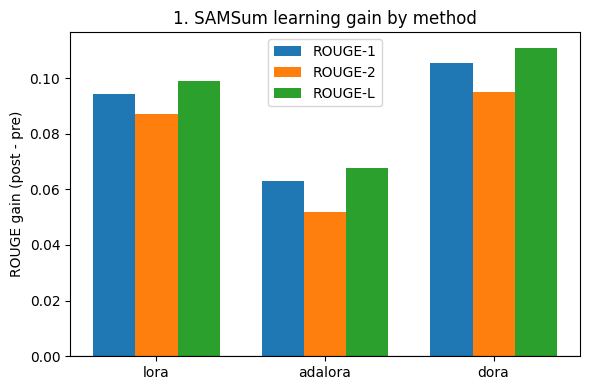

In [51]:
methods = comparison_df["peft_method"].tolist()

fig1, ax1 = plt.subplots(figsize=(6, 4))
x = np.arange(len(methods))
width = 0.25
ax1.bar(x - width, comparison_df["samsum_rouge1_gain"], width, label="ROUGE-1")
ax1.bar(x, comparison_df["samsum_rouge2_gain"], width, label="ROUGE-2")
ax1.bar(x + width, comparison_df["samsum_rougeL_gain"], width, label="ROUGE-L")
ax1.set_xticks(x)
ax1.set_xticklabels(methods)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_ylabel("ROUGE gain (post - pre)")
ax1.set_title("1. SAMSum learning gain by method")
ax1.legend()
plt.tight_layout()
plt.show()


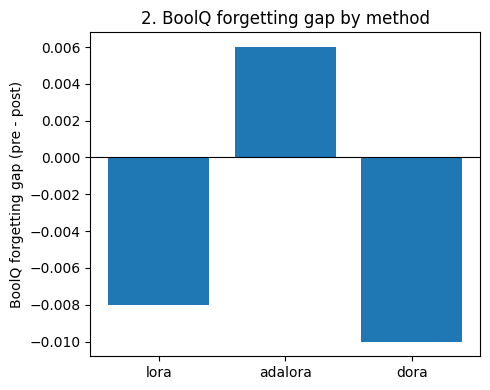

In [52]:
fig2, ax2 = plt.subplots(figsize=(5, 4))
ax2.bar(methods, comparison_df["boolq_forgetting_gap"])
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_ylabel("BoolQ forgetting gap (pre - post)")
ax2.set_title("2. BoolQ forgetting gap by method")
plt.tight_layout()
plt.show()


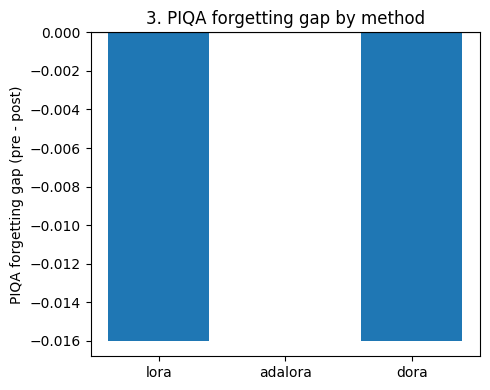

In [53]:
fig3, ax3 = plt.subplots(figsize=(5, 4))
ax3.bar(methods, comparison_df["piqa_forgetting_gap"])
ax3.axhline(0, color="black", linewidth=0.8)
ax3.set_ylabel("PIQA forgetting gap (pre - post)")
ax3.set_title("3. PIQA forgetting gap by method")
plt.tight_layout()
plt.show()


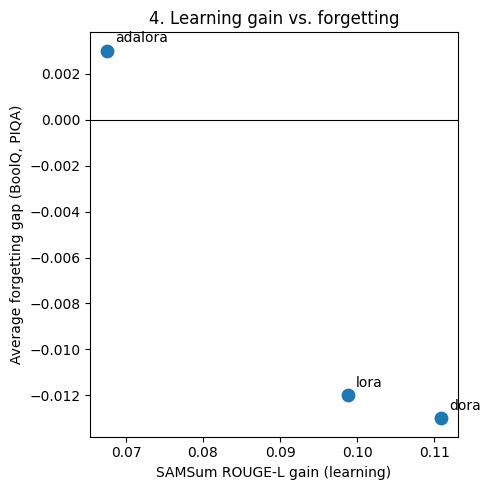

In [54]:
fig4, ax4 = plt.subplots(figsize=(5, 5))
avg_forgetting = (comparison_df["boolq_forgetting_gap"] + comparison_df["piqa_forgetting_gap"]) / 2
ax4.scatter(comparison_df["samsum_rougeL_gain"], avg_forgetting, s=80)
for i, m in enumerate(methods):
    ax4.annotate(m, (comparison_df["samsum_rougeL_gain"].iloc[i], avg_forgetting.iloc[i]),
                 textcoords="offset points", xytext=(6, 6))
ax4.axhline(0, color="black", linewidth=0.8)
ax4.set_xlabel("SAMSum ROUGE-L gain (learning)")
ax4.set_ylabel("Average forgetting gap (BoolQ, PIQA)")
ax4.set_title("4. Learning gain vs. forgetting")
plt.tight_layout()
plt.show()


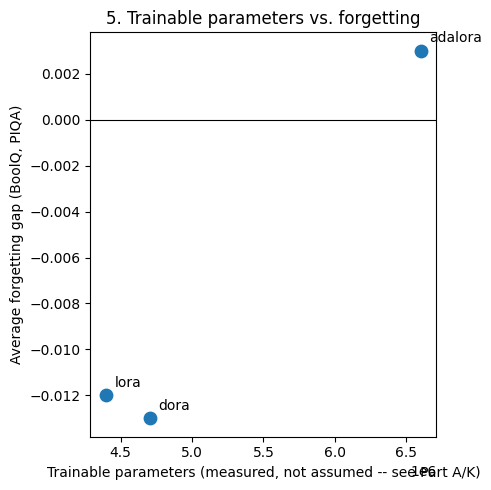

In [55]:
fig5, ax5 = plt.subplots(figsize=(5, 5))
ax5.scatter(comparison_df["trainable_parameters"], avg_forgetting, s=80)
for i, m in enumerate(methods):
    ax5.annotate(m, (comparison_df["trainable_parameters"].iloc[i], avg_forgetting.iloc[i]),
                 textcoords="offset points", xytext=(6, 6))
ax5.axhline(0, color="black", linewidth=0.8)
ax5.set_xlabel("Trainable parameters (measured, not assumed -- see Part A/K)")
ax5.set_ylabel("Average forgetting gap (BoolQ, PIQA)")
ax5.set_title("5. Trainable parameters vs. forgetting")
plt.tight_layout()
plt.show()


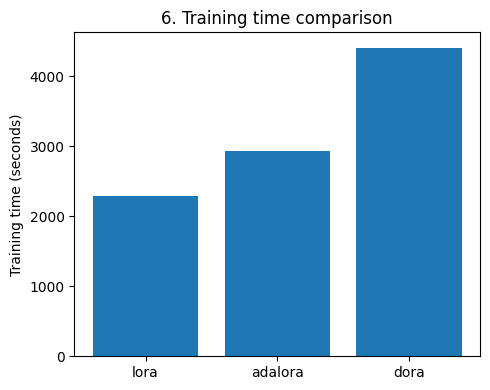

In [56]:
fig6, ax6 = plt.subplots(figsize=(5, 4))
ax6.bar(methods, comparison_df["training_time_seconds"])
ax6.set_ylabel("Training time (seconds)")
ax6.set_title("6. Training time comparison")
plt.tight_layout()
plt.show()


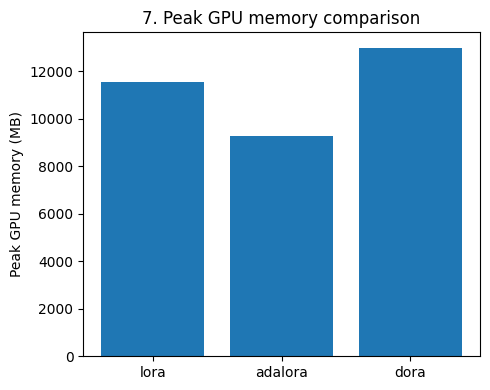

In [57]:
fig7, ax7 = plt.subplots(figsize=(5, 4))
ax7.bar(methods, comparison_df["peak_gpu_memory_mb"])
ax7.set_ylabel("Peak GPU memory (MB)")
ax7.set_title("7. Peak GPU memory comparison")
plt.tight_layout()
plt.show()


## PART L (continued) -- Scientific Interpretation

**Forgetting gap sign convention (restated, exactly):**
- **Positive** forgetting gap: probe performance *decreased* after fine-tuning.
- **Zero**: no measured change.
- **Negative**: probe score *improved* after fine-tuning. This is **not**
  "negative forgetting" as a psychological concept -- it is simply an
  improvement on that probe in this one run. Do not narrate it as the model
  "un-forgetting" something.

**Do not claim statistical significance.** Every number above comes from
**one run per method, one seed**. A smaller |forgetting gap| for one method
than another in this run is an observation about this run, not a
demonstrated property of the method. That claim requires the multi-seed
sweep planned for later (README Week 2, day 9) -- not performed here.

**Do not automatically conclude "smallest forgetting gap = best method."**
A method that barely changes on BoolQ/PIQA but also barely learns SAMSum
hasn't "won" anything -- it just didn't move much in either direction. The
comparison that matters is the trade-off, not any single axis in isolation:

- **Target-task learning** (SAMSum ROUGE gain) vs.
- **Retention** (BoolQ/PIQA forgetting gap) vs.
- **Parameter cost** (trainable parameters/%; recall View A does *not*
  equalize these -- Part K's cross-check table shows the actual measured
  counts) vs.
- **Compute cost** (training time, peak GPU memory -- AdaLoRA's
  update-and-allocate bookkeeping and DoRA's per-forward-pass norm
  computation are both expected to add some training-time overhead over
  plain LoRA; that's part of what's being measured, not a flaw).

A method that learns more but forgets more, at a higher parameter and
compute cost, is not strictly "worse" or "better" than one that learns less
but forgets less cheaply -- which trade-off matters depends on the
downstream use case. State the trade-off explicitly rather than collapsing
it into a single winner.


In [58]:
stage("Descriptive-only observations (NOT conclusions -- see markdown above)")

best_learning = comparison_df.loc[comparison_df["samsum_rougeL_gain"].idxmax(), "peft_method"]
smallest_boolq_gap = comparison_df.loc[comparison_df["boolq_forgetting_gap"].abs().idxmin(), "peft_method"]
smallest_piqa_gap = comparison_df.loc[comparison_df["piqa_forgetting_gap"].abs().idxmin(), "peft_method"]
fewest_params = comparison_df.loc[comparison_df["trainable_parameters"].idxmin(), "peft_method"]
fastest = comparison_df.loc[comparison_df["training_time_seconds"].idxmin(), "peft_method"]
lowest_memory = comparison_df.loc[comparison_df["peak_gpu_memory_mb"].idxmin(), "peft_method"]

print(f"In THIS single run: largest SAMSum ROUGE-L gain     -> {best_learning}")
print(f"In THIS single run: smallest |BoolQ forgetting gap| -> {smallest_boolq_gap}")
print(f"In THIS single run: smallest |PIQA forgetting gap|  -> {smallest_piqa_gap}")
print(f"In THIS single run: fewest trainable parameters     -> {fewest_params}")
print(f"In THIS single run: fastest training time           -> {fastest}")
print(f"In THIS single run: lowest peak GPU memory           -> {lowest_memory}")
print("\nThese are descriptive observations about one run, not claims about which method is")
print("generally better -- see the interpretation markdown above before drawing any conclusion.")



Descriptive-only observations (NOT conclusions -- see markdown above)
In THIS single run: largest SAMSum ROUGE-L gain     -> dora
In THIS single run: smallest |BoolQ forgetting gap| -> adalora
In THIS single run: smallest |PIQA forgetting gap|  -> adalora
In THIS single run: fewest trainable parameters     -> lora
In THIS single run: fastest training time           -> lora
In THIS single run: lowest peak GPU memory           -> adalora

These are descriptive observations about one run, not claims about which method is
generally better -- see the interpretation markdown above before drawing any conclusion.


## Persistent output location
Phase 2 recovery artifacts are stored in `MyDrive/forgetting-aware-peft/phase2_resume/` with separate `checkpoints`, `adapters`, and `results` folders. Do not delete this folder until the project is complete.
